# Detección temprana de daño en el puente Z24 con machine learning

Proyecto de machine learning sobre los datos del monitoreo continuo (EMS) del puente Z24. Se entrena un modelo que predice la frecuencia de cada modo a partir de la temperatura, solo con el puente sano, y se vigila la diferencia entre lo medido y lo predicho para detectar el daño lo antes posible.

Parte de los resultados de los notebooks de la carpeta superior: `results/ems_natural_frequencies.csv` (frecuencias de los modos 1, 2 y 3 en cada medición horaria, de `z24_natural_frequencies_ems.ipynb`) y `cache/ems_inventory.csv` (variables ambientales de cada medición, de `z24_data_structure.ipynb`).

**Índice**
1. [Definición del problema y alcance](#sec1)
2. [Selección y limpieza de datos](#sec2)
3. [Ingeniería de variables](#sec3)
4. [Primer modelo: regresión lineal](#sec4)
5. [Modelo no lineal: random forest](#sec5)
6. [Ajuste de hiperparámetros del random forest](#sec6)
7. [Índice de daño: distancia de Mahalanobis](#sec7)
8. [Carta de control EWMA y límite de alarma](#sec8)
9. [Evaluación](#sec9)
10. [Modelo físico (caja gris)](#sec10)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import roc_auc_score, roc_curve

# Fixed seed, so that any random result is always the same
np.random.seed(42)

# Input files (they are in the parent folder, bridge-z24)
FREQUENCIES_FILE = "../results/ems_natural_frequencies.csv"
ENVIRONMENT_FILE = "../cache/ems_inventory.csv"

# Important dates
TEST_START = pd.Timestamp("1998-07-15")           # start of the healthy test block
PREP_START = pd.Timestamp("1998-08-05")           # start of the installation of the pier lowering system
DAMAGE_START = pd.Timestamp("1998-08-11 13:15")   # first pier lowering, -20 mm (Table 8, Appendix F of C11)


# Shows a table with its caption above it (decimal numbers are shown with the given number of decimals)
def show_table(table, number, caption, decimals=2):
    display(Markdown(f"**Tabla {number}.** {caption}"))
    display(table.style.hide(axis="index").format(precision=decimals))


# Shows a figure with its caption below it
def show_figure(fig, number, caption):
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

---
<a id="sec1"></a>
## 1. Definición del problema y alcance

### 1.1 Problema

- El daño reduce la rigidez del puente y, por lo tanto, sus frecuencias naturales. Vigilar las frecuencias es una forma barata de detectar daño.
- Pero la temperatura también cambia las frecuencias, y en Z24 lo hace en un orden parecido al del daño. Bajo 0 °C el cambio es mayor y no lineal, porque el asfalto y el suelo se congelan y rigidizan el puente.
- Si se compara la frecuencia medida con la de todo el año, el daño queda escondido dentro de la variación por temperatura (Figura 1).

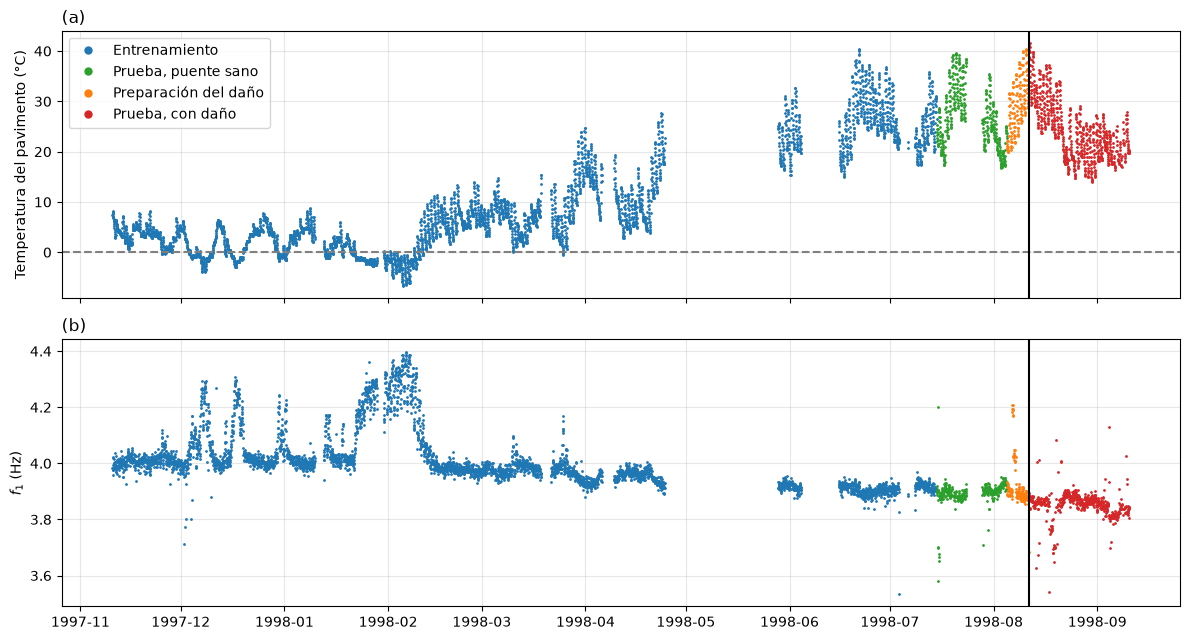

**Figura 1.** Monitoreo del Z24, del 10.11.1997 al 10.09.1998: (a) temperatura del pavimento y (b) frecuencia del modo 1. Los colores son los bloques de tiempo del proyecto (sección 1.5). La línea vertical marca el primer daño (descenso de la pila, 11.08.1998, 13:15) y la discontinua de (a), 0 °C.

In [2]:
# 1. Read the natural frequencies (f1, f2, f3) of each hourly measurement
frequencies = pd.read_csv(FREQUENCIES_FILE, parse_dates=["start"])

# 2. Read the two pavement temperature sensors (TP1 and TP2) of each measurement
temperatures = pd.read_csv(ENVIRONMENT_FILE, usecols=["code", "TP1", "TP2"])

# 3. Some readings are error codes of the data logger (for example 3276.7).
#    A real temperature is never above 100 °C, so those values are replaced by NaN (empty)
temperatures.loc[temperatures["TP1"].abs() >= 100, "TP1"] = np.nan
temperatures.loc[temperatures["TP2"].abs() >= 100, "TP2"] = np.nan

# 4. Pavement temperature T = average of the two sensors (if one is empty, the other one is used)
temperatures["T"] = temperatures[["TP1", "TP2"]].mean(axis=1)

# 5. Join both tables using the code of the measurement
data = pd.merge(frequencies, temperatures[["code", "T"]], on="code", how="left")


# 6. Assign each measurement to a time block (Section 1.5)
def get_block(date):
    if date < TEST_START:
        return "Entrenamiento"
    elif date < PREP_START:
        return "Prueba, puente sano"
    elif date < DAMAGE_START:
        return "Preparación del daño"
    else:
        return "Prueba, con daño"


data["block"] = data["start"].apply(get_block)

# 7. Plot the temperature and f1 over time, with one color per block
BLOCK_COLORS = {
    "Entrenamiento": "tab:blue",
    "Prueba, puente sano": "tab:green",
    "Preparación del daño": "tab:orange",
    "Prueba, con daño": "tab:red",
}

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)

for block, color in BLOCK_COLORS.items():
    block_data = data[data["block"] == block]
    axes[0].plot(block_data["start"], block_data["T"], ".", markersize=2, color=color, label=block)
    axes[1].plot(block_data["start"], block_data["f1"], ".", markersize=2, color=color)

# (a) Temperature
axes[0].axhline(0, color="gray", linestyle="--")        # 0 °C
axes[0].axvline(DAMAGE_START, color="black")            # first damage
axes[0].set_ylabel("Temperatura del pavimento (°C)")
axes[0].set_title("(a)", loc="left")
axes[0].legend(markerscale=5, loc="upper left")
axes[0].grid(alpha=0.3)

# (b) Natural frequency of mode 1
axes[1].axvline(DAMAGE_START, color="black")            # first damage
axes[1].set_ylabel("$f_1$ (Hz)")
axes[1].set_title("(b)", loc="left")
axes[1].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 1, "Monitoreo del Z24, del 10.11.1997 al 10.09.1998: (a) temperatura del pavimento y (b) "
            "frecuencia del modo 1. Los colores son los bloques de tiempo del proyecto (sección 1.5). La línea "
            "vertical marca el primer daño (descenso de la pila, 11.08.1998, 13:15) y la discontinua de (a), 0 °C.")

- La frecuencia del modo 1 sube en invierno y baja en verano, siguiendo a la temperatura. Los picos más altos coinciden con las heladas.
- Con daño (rojo), $f_1$ baja unos 0.05 Hz respecto al verano sano, mientras que entre invierno y verano la temperatura la mueve más de 0.4 Hz.
- Además, el daño ocurre en la época más caliente, cuando $f_1$ ya es la más baja del año. Sin corregir por temperatura, cuesta separar el efecto del daño del efecto del calor.
- Hay mediciones sueltas muy alejadas de la nube (por ejemplo, bajo 3.7 Hz). Se tratan en la sección 2.4.

### 1.2 Objetivo

Detectar el daño del Z24 lo antes posible y con pocas falsas alarmas, quitando primero el efecto de la temperatura con un modelo de machine learning.

**Pregunta del proyecto:** con una tasa de falsas alarmas fijada en el puente sano, ¿cuántas horas después del primer daño se detecta?

### 1.3 Enfoque

Es un problema de **detección de novedades** (*novelty detection*): el modelo se entrena solo con el puente sano y aprende lo que es "normal". Las etiquetas de sano y dañado no se usan para entrenar, solo para evaluar.

1. **Modelo de regresión:** predice la frecuencia de cada modo, $\hat{f}_m$, a partir de la temperatura y de las variables que se derivan de ella (sección 1.4).
2. **Residuo:** diferencia entre lo medido y lo predicho,

$$
r_{m,i} = f_{m,i} - \hat{f}_m(\mathbf{x}_i)
\tag{1}
$$

donde $f_{m,i}$ es la frecuencia medida del modo $m$ en la medición $i$, $\mathbf{x}_i$ el vector de variables de entrada de esa medición y $\hat{f}_m(\mathbf{x}_i)$ la frecuencia que predice el modelo. Si el modelo es bueno, en el puente sano el residuo es pequeño y no depende de la temperatura.

3. **Índice de daño:** los residuos de los tres modos se combinan en uno solo con la distancia de Mahalanobis, que tiene en cuenta que los residuos de los modos están correlacionados.
4. **Carta de control:** el índice se suaviza con una media móvil exponencial (EWMA, *Exponentially Weighted Moving Average*), que da más peso a las mediciones recientes:

$$
z_i = \lambda\, d_i + (1 - \lambda)\, z_{i-1}
\tag{2}
$$

donde $d_i$ es el índice de daño de la medición $i$, $z_i$ el valor suavizado y $\lambda \in (0, 1]$ el peso de la medición nueva. Con $\lambda$ pequeño, el ruido de una hora no dispara la alarma, pero un cambio que se mantiene sí. Se comparará también con CUSUM (suma acumulada).

5. **Alarma:** cuando $z_i$ pasa un límite calibrado con los residuos del puente sano que el modelo no vio.

### 1.4 Variables

**Tabla 1.** Variables del modelo.

| Tipo | Variable | Por qué |
|---|---|---|
| Salida | $f_1$, $f_2$, $f_3$ (Hz) | Frecuencias de los tres modos identificados en el EMS |
| Entrada | Temperatura del pavimento, $T$ (°C), promedio de `TP1` y `TP2` | Es la que más se correlaciona con las frecuencias; bajo 0 °C la rigidización viene del asfalto |
| Entrada | Medias móviles de $T$ (6, 12 y 24 h) | El puente tarda en calentarse y enfriarse (inercia térmica) |
| Entrada, variante A | Horas seguidas con $T < 0$ °C | La rigidización depende de cuánto tiempo lleva congelado el puente |
| Entrada, variante B | Grados-hora de helada: suma $-T$ en cada hora bajo 0 °C y resta $T$ en cada hora sobre 0 °C, sin bajar de 0 | Mide también la intensidad de la helada y hace gradual el deshielo |

- Se prueba primero la variante A, después la B y después las dos juntas, y se queda la que dé mejores resultados.
- La humedad, el viento y las otras temperaturas (aire, suelo, cajón) no se usan. La sección 2 muestra con las gráficas de frecuencia frente a temperatura por qué basta con la del pavimento y su historia.

### 1.5 División temporal de los datos

**Por qué no al azar.** Las mediciones horarias seguidas son casi iguales: la temperatura y la frecuencia cambian poco de una hora a la siguiente. Con una división aleatoria, cada hora de prueba tendría a sus vecinas en el entrenamiento, y el modelo acertaría por haber visto casi el mismo dato (fuga de datos, *data leakage*). El error saldría demasiado optimista. En el monitoreo real el modelo siempre predice semanas que no vio, y la división tiene que imitar eso.

**División.** Los datos se separan en bloques de tiempo (Tabla 2 y colores de la Figura 1):

- **Entrenamiento**, con validación cruzada por semanas: el bloque se divide en $k$ folds formados por semanas completas. Cada fold se predice con un modelo entrenado con los demás. Así:
  - se eligen el modelo, la variante de helada y los hiperparámetros;
  - cada hora del entrenamiento, también las de helada, recibe una predicción de un modelo que no vio su semana. Con esos residuos se calibra el límite de alarma y se miden las falsas alarmas bajo y sobre 0 °C.
- **Prueba, puente sano:** las 3 semanas antes de la preparación del daño. No se usa para ajustar nada. Comprueba las falsas alarmas en las mismas condiciones (verano) que el periodo con daño.
- **Prueba, con daño:** mide el retraso de detección.

Una semana es más larga que la inercia térmica del puente (horas a pocos días), así que las semanas de distintos folds no se parecen hora a hora. En la sección de entrenamiento se comprueba con la autocorrelación de los residuos.

In [3]:
# What each block is used for
BLOCK_USE = {
    "Entrenamiento": "Validación cruzada por semanas: elegir el modelo y calibrar el límite de alarma con todas las temperaturas",
    "Prueba, puente sano": "Comprobar las falsas alarmas en las condiciones del periodo con daño (verano)",
    "Preparación del daño": "Se excluye de todo el proyecto: la instalación del sistema para bajar la pila cambió las frecuencias",
    "Prueba, con daño": "Medir el retraso de detección y el porcentaje de horas detectadas",
}

# One row per block: first date, last date and number of measurements
rows = []
for block in BLOCK_COLORS:
    block_data = data[data["block"] == block]
    rows.append({
        "Bloque": block,
        "Desde": block_data["start"].min().strftime("%d.%m.%Y %H:%M"),
        "Hasta": block_data["start"].max().strftime("%d.%m.%Y %H:%M"),
        "Mediciones": len(block_data),
        "Uso": BLOCK_USE[block],
    })
blocks_table = pd.DataFrame(rows)

show_table(blocks_table, 2, "Bloques de tiempo del proyecto.")

**Tabla 2.** Bloques de tiempo del proyecto.

Bloque,Desde,Hasta,Mediciones,Uso
Entrenamiento,10.11.1997 14:00,14.07.1998 23:00,4431,Validación cruzada por semanas: elegir el modelo y calibrar el límite de alarma con todas las temperaturas
"Prueba, puente sano",15.07.1998 00:00,04.08.1998 23:00,390,Comprobar las falsas alarmas en las condiciones del periodo con daño (verano)
Preparación del daño,05.08.1998 00:00,11.08.1998 13:00,158,Se excluye de todo el proyecto: la instalación del sistema para bajar la pila cambió las frecuencias
"Prueba, con daño",11.08.1998 14:00,10.09.1998 13:00,674,Medir el retraso de detección y el porcentaje de horas detectadas


**Folds de la validación cruzada.** En la Figura 1 el azul es todo el entrenamiento y el verde la prueba sana. Dentro del entrenamiento, la validación cruzada separa además semanas de validación, que cambian en cada fold:

- Cada medición recibe un número de semana, contado desde la primera medición (semana 0, 1, 2, ...).
- Las semanas se reparten por turnos en $k = 5$ folds: la semana 0 va al fold 1, la 1 al fold 2, ..., la 4 al fold 5, la 5 de nuevo al fold 1, y así sucesivamente.
- En cada vuelta de la validación, un fold es la validación y los otros cuatro el entrenamiento.

Al repartir por turnos, cada fold tiene semanas de todo el año, de invierno a verano (Figura 2 y Tabla 3).

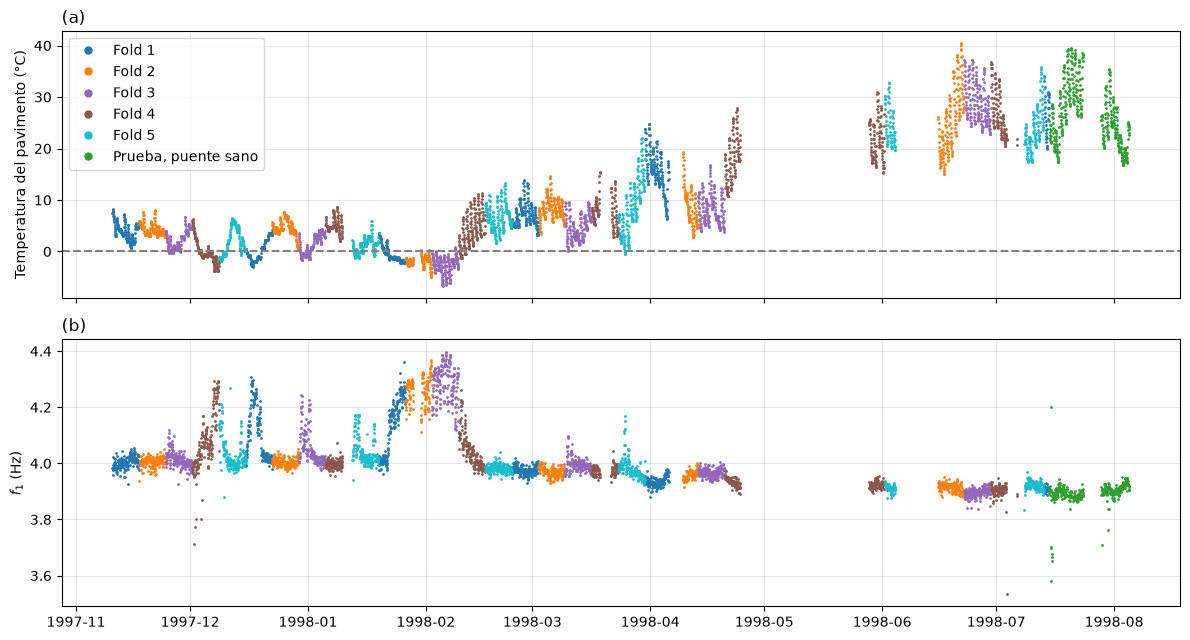

**Figura 2.** Folds de la validación cruzada en el bloque de entrenamiento (10.11.1997 al 14.07.1998) y prueba sana (15.07.1998 al 04.08.1998): (a) temperatura del pavimento y (b) frecuencia del modo 1. Cada color es un fold; cada tramo de un color es una semana completa. La línea discontinua de (a) marca 0 °C.

**Tabla 3.** Semanas, mediciones y rango de temperatura del pavimento de cada fold.

Fold,Semanas,Mediciones,T mínima (°C),T máxima (°C),Mediciones bajo 0 °C
1,6,855,-3.0,34.1,214
2,6,874,-5.0,40.4,119
3,6,1008,-6.7,37.3,237
4,7,831,-3.9,36.7,128
5,6,863,-1.8,35.7,101


In [4]:
# 1. Keep only the training block
training = data[data["block"] == "Entrenamiento"].copy()

# 2. Week number of each measurement, counted from the first measurement (week 0, 1, 2, ...)
first_date = training["start"].min()
training["week"] = (training["start"] - first_date).dt.days // 7

# 3. Assign the weeks to the folds in turn: week 0 -> fold 1, week 1 -> fold 2, ..., week 5 -> fold 1 again
N_FOLDS = 5
training["fold"] = training["week"] % N_FOLDS + 1

# 4. Plot the temperature and f1 over time, with one color per fold
FOLD_COLORS = {1: "tab:blue", 2: "tab:orange", 3: "tab:purple", 4: "tab:brown", 5: "tab:cyan"}
healthy_test = data[data["block"] == "Prueba, puente sano"]

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)

for fold, color in FOLD_COLORS.items():
    fold_data = training[training["fold"] == fold]
    axes[0].plot(fold_data["start"], fold_data["T"], ".", markersize=2, color=color, label=f"Fold {fold}")
    axes[1].plot(fold_data["start"], fold_data["f1"], ".", markersize=2, color=color)

axes[0].plot(healthy_test["start"], healthy_test["T"], ".", markersize=2, color="tab:green", label="Prueba, puente sano")
axes[1].plot(healthy_test["start"], healthy_test["f1"], ".", markersize=2, color="tab:green")

# (a) Temperature
axes[0].axhline(0, color="gray", linestyle="--")        # 0 °C
axes[0].set_ylabel("Temperatura del pavimento (°C)")
axes[0].set_title("(a)", loc="left")
axes[0].legend(markerscale=5, loc="upper left")
axes[0].grid(alpha=0.3)

# (b) Natural frequency of mode 1
axes[1].set_ylabel("$f_1$ (Hz)")
axes[1].set_title("(b)", loc="left")
axes[1].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 2, "Folds de la validación cruzada en el bloque de entrenamiento (10.11.1997 al 14.07.1998) y "
            "prueba sana (15.07.1998 al 04.08.1998): (a) temperatura del pavimento y (b) frecuencia del modo 1. Cada "
            "color es un fold; cada tramo de un color es una semana completa. La línea discontinua de (a) marca 0 °C.")

# 5. Table: weeks, measurements and temperature range of each fold
rows = []
for fold in FOLD_COLORS:
    fold_data = training[training["fold"] == fold]
    rows.append({
        "Fold": fold,
        "Semanas": fold_data["week"].nunique(),
        "Mediciones": len(fold_data),
        "T mínima (°C)": fold_data["T"].min(),
        "T máxima (°C)": fold_data["T"].max(),
        "Mediciones bajo 0 °C": (fold_data["T"] < 0).sum(),
    })
folds_table = pd.DataFrame(rows)

show_table(folds_table, 3, "Semanas, mediciones y rango de temperatura del pavimento de cada fold.", decimals=1)

- Los cinco folds tienen entre 6 y 7 semanas y entre 831 y 1008 mediciones.
- Todos cubren casi todo el rango de temperatura, de bajo 0 °C a más de 34 °C, y todos tienen entre 101 y 237 mediciones con helada. Así, cada fold de validación pone a prueba al modelo en invierno y en verano.
- La semana más fría (hasta −6.7 °C) queda en el fold 3. Cuando ese fold es la validación, el modelo no vio temperaturas tan bajas y tiene que extrapolar.

- **Preparación del daño.** Del 05.08.1998 al primer descenso de la pila se instaló el sistema para bajarla: se cortaron tres tramos de la pila Koppigen y se reemplazaron por piezas de acero con gatos hidráulicos (Tabla 2 de `z24_modal_distributions.ipynb`). Eso cambió el puente sano, por ejemplo $f_2$ quedó debajo de la nube del resto del periodo sano. Por eso estas mediciones se excluyen del entrenamiento, de la prueba y de las métricas, como en ese notebook, donde el puente sano es solo lo anterior al 05.08.1998.
- La prueba sana termina el 04.08.1998 y la prueba con daño empieza el 11.08.1998. La carta de control pasa del último dato sano al primero con daño, saltándose la preparación.
- **Limitación.** La semana más fría (2 al 8 de febrero de 1998, hasta −6.7 °C) no tiene otra parecida. En el fold en que queda fuera del entrenamiento, el modelo tiene que extrapolar, y su error será mayor. Es lo que pasaría con un invierno más frío que el de los datos.

### 1.6 Métricas

- **Del modelo:** RMSE (*root mean square error*, raíz del error cuadrático medio) de los residuos en la validación cruzada (por separado bajo y sobre 0 °C) y en la prueba sana.
- **De la detección:**
  - Tasa de falsas alarmas: porcentaje de horas en alarma en la validación cruzada (bajo y sobre 0 °C) y en la prueba sana.
  - Retraso de detección: horas desde el primer daño (11.08.1998, 13:15) hasta la primera alarma.
  - Porcentaje de horas en alarma en la prueba con daño.
  - Curva ROC (*Receiver Operating Characteristic*): detecciones frente a falsas alarmas para todos los límites posibles.
- **Comparación:** sin corrección por temperatura, con el modelo bilineal (`z24_modal_distributions.ipynb`) y con los modelos de machine learning, de menos a más complejo (regresión lineal, proceso gaussiano o gradient boosting, red neuronal pequeña).

### 1.7 Fuera del alcance

- La identificación modal desde las aceleraciones: se parte de las frecuencias ya identificadas.
- Localizar o cuantificar el daño: solo se detecta.
- Las formas modales.
- Otros puentes.

---
<a id="sec2"></a>
## 2. Selección y limpieza de datos

### 2.1 Selección de las variables

La Figura 3 muestra la frecuencia de cada modo frente a la temperatura del pavimento en el bloque de entrenamiento.

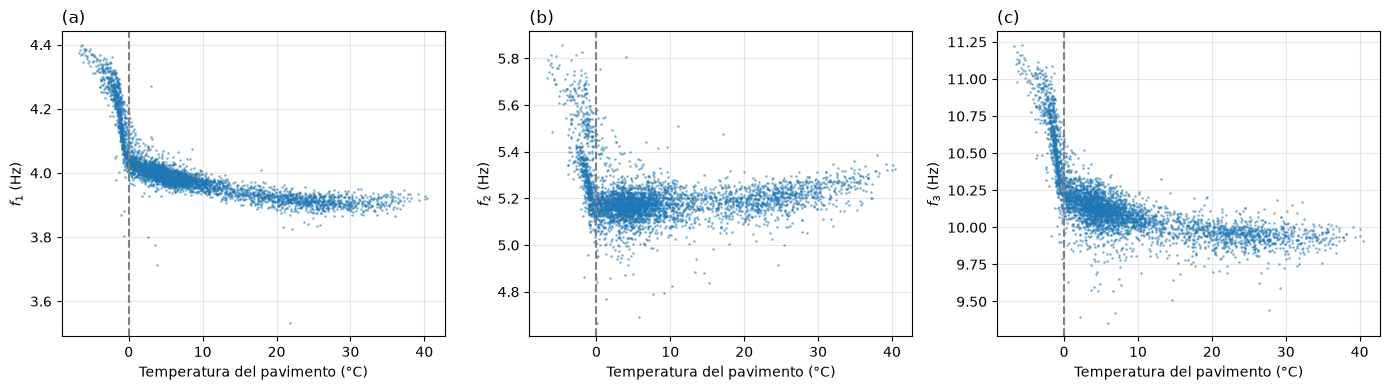

**Figura 3.** Frecuencia natural frente a la temperatura del pavimento en el bloque de entrenamiento (10.11.1997 al 14.07.1998): (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.

In [5]:
PANEL_LABELS = ["(a)", "(b)", "(c)"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for i, mode in enumerate([1, 2, 3]):
    axes[i].plot(training["T"], training[f"f{mode}"], ".", markersize=2, alpha=0.4)
    axes[i].axvline(0, color="gray", linestyle="--")     # 0 °C
    axes[i].set_xlabel("Temperatura del pavimento (°C)")
    axes[i].set_ylabel(f"$f_{mode}$ (Hz)")
    axes[i].set_title(PANEL_LABELS[i], loc="left")
    axes[i].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 3, "Frecuencia natural frente a la temperatura del pavimento en el bloque de entrenamiento "
            "(10.11.1997 al 14.07.1998): (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.")

- **La relación no es lineal.** Sobre 0 °C, $f_1$ y $f_3$ bajan poco a poco al subir la temperatura, y $f_2$ casi no cambia (hasta sube un poco con el calor). Bajo 0 °C las tres suben con fuerza: el asfalto se congela y rigidiza el puente. Una recta no puede representar los dos tramos, y por eso se prueban modelos no lineales.
- **La temperatura sola no basta.** Entre −1 y 0 °C, con casi la misma temperatura, $f_1$ va de unos 4.05 a 4.3 Hz. La diferencia depende de cuánto tiempo lleva helando: el asfalto tarda en congelarse y en descongelarse. Por eso se agregan las medias móviles de la temperatura y el tiempo bajo cero (Tabla 1). Se calculan en la sección 3.
- Las otras variables ambientales (humedad, viento, temperaturas del aire y del suelo) no se usan (sección 1.4).

### 2.2 Valores faltantes

Una medición puede no tener la frecuencia de un modo porque en `z24_natural_frequencies_ems.ipynb` no se identificó ese modo (MAC menor que 0.7 con la forma de referencia). La temperatura puede faltar si los dos sensores del pavimento dieron un código de error.

In [6]:
# Number of empty values (NaN) of each variable in each block
rows = []
for block in BLOCK_COLORS:
    block_data = data[data["block"] == block]
    rows.append({
        "Bloque": block,
        "Mediciones": len(block_data),
        "f1 vacía": block_data["f1"].isna().sum(),
        "f2 vacía": block_data["f2"].isna().sum(),
        "f3 vacía": block_data["f3"].isna().sum(),
        "T vacía": block_data["T"].isna().sum(),
    })
missing_table = pd.DataFrame(rows)

show_table(missing_table, 4, "Mediciones sin frecuencia o sin temperatura en cada bloque.")

**Tabla 4.** Mediciones sin frecuencia o sin temperatura en cada bloque.

Bloque,Mediciones,f1 vacía,f2 vacía,f3 vacía,T vacía
Entrenamiento,4431,6,88,90,0
"Prueba, puente sano",390,47,2,43,0
Preparación del daño,158,4,0,47,0
"Prueba, con daño",674,103,12,135,1


- En el entrenamiento faltan sobre todo $f_2$ y $f_3$ (unas 90 mediciones cada una, el 2 %). La temperatura falta en una sola medición, del periodo con daño.
- En el periodo con daño falta mucho más: 180 de 674 mediciones (27 %) no tienen alguna frecuencia (Tabla 6). Posiblemente el daño cambia las formas modales y el MAC con la forma de referencia del puente sano baja de 0.7. Eso también es una señal de daño, pero este proyecto solo usa las frecuencias identificadas (limitación).
- **Decisión:** se eliminan las mediciones a las que les falta alguna frecuencia o la temperatura. No se rellenan (imputan): una frecuencia inventada no aporta información del puente, y el índice de daño (sección 1.3) necesita los tres modos a la vez.
- La temperatura de esas mediciones sí se usa para calcular la historia de la temperatura (sección 3), porque la temperatura existe aunque falte la frecuencia.

### 2.3 Huecos en el tiempo

El EMS mide cada hora, pero hay horas sin medición. Los huecos importan para las variables de la sección 3: una media móvil de 24 h o las horas seguidas bajo cero no se pueden calcular bien si faltan días.

In [7]:
# 1. Sort all the measurements by date
all_measurements = data.sort_values("start").copy()

# 2. Hours between each measurement and the previous one
all_measurements["previous_start"] = all_measurements["start"].shift(1)
all_measurements["hours_since_previous"] = (all_measurements["start"] - all_measurements["previous_start"]).dt.total_seconds() / 3600

# 3. Keep the gaps longer than one day
gaps = all_measurements[all_measurements["hours_since_previous"] > 24]

rows = []
for _, gap in gaps.iterrows():
    rows.append({
        "Última medición antes del hueco": gap["previous_start"].strftime("%d.%m.%Y %H:%M"),
        "Primera medición después del hueco": gap["start"].strftime("%d.%m.%Y %H:%M"),
        "Horas sin medición": round(gap["hours_since_previous"]),
        "Días sin medición": gap["hours_since_previous"] / 24,
    })
gaps_table = pd.DataFrame(rows)

print(f"Gaps of 2 to 24 hours: {((all_measurements['hours_since_previous'] > 1.5) & (all_measurements['hours_since_previous'] <= 24)).sum()}")
show_table(gaps_table, 5, "Huecos de más de un día entre dos mediciones seguidas (todas las mediciones del EMS).", decimals=1)

Gaps of 2 to 24 hours: 42


**Tabla 5.** Huecos de más de un día entre dos mediciones seguidas (todas las mediciones del EMS).

Última medición antes del hueco,Primera medición después del hueco,Horas sin medición,Días sin medición
10.01.1998 01:00,12.01.1998 17:00,64,2.7
28.01.1998 16:00,30.01.1998 15:00,47,2.0
18.03.1998 18:00,21.03.1998 17:00,71,3.0
05.04.1998 21:00,09.04.1998 13:00,88,3.7
24.04.1998 16:00,28.05.1998 14:00,814,33.9
04.06.1998 11:00,15.06.1998 18:00,271,11.3
03.07.1998 18:00,06.07.1998 09:00,63,2.6
06.07.1998 10:00,08.07.1998 10:00,48,2.0
23.07.1998 20:00,28.07.1998 15:00,115,4.8


- Hay 9 huecos de más de un día. El más largo es de 34 días, entre el 24.04 y el 28.05.1998.
- Hay además 42 huecos cortos, de 2 a 9 horas.
- **Decisión:** los huecos no se rellenan. En la sección 3, las medias móviles se calculan solo con las mediciones que caen dentro de su ventana, y las horas seguidas bajo cero vuelven a 0 después de un hueco largo.

### 2.4 Valores atípicos

Las Figuras 1 y 3 muestran mediciones sueltas muy lejos del resto, por ejemplo $f_1$ bajo 3.8 Hz en diciembre. Son, casi seguro, errores de identificación del modo: la frecuencia del puente no puede saltar 0.2 Hz en una hora y volver a la siguiente.

**Decisión: no se eliminan.** En el monitoreo también van a aparecer errores de este tipo, y no se pueden quitar a mano. Si el entrenamiento se limpia y el monitoreo no:

- el modelo y el límite de alarma se calibran con datos más "limpios" que los que después tienen que vigilar;
- el límite queda demasiado ajustado, y cada error de identificación en el monitoreo puede dar una falsa alarma.

Dejándolos, el límite de alarma se calibra con la misma calidad de datos que tendrá el monitoreo. Además, la carta de control EWMA (Ec. 2) da poco peso a una medición aislada, así que un error suelto no debería disparar la alarma; un daño, que se mantiene en el tiempo, sí.

### 2.5 Mediciones excluidas y datos que quedan

Solo se excluyen dos grupos de mediciones:

1. **Las de la preparación del daño** (05.08.1998 al 11.08.1998, 13:15): 158 mediciones. La instalación del sistema para bajar la pila cambió las frecuencias del puente sano (sección 1.5), así que no representan ni al puente sano ni al dañado.
2. **Las que no tienen alguna frecuencia o la temperatura** (sección 2.2): sin el valor medido no hay nada que predecir ni que comparar.

La Figura 4 muestra por qué se excluye la preparación del daño. Después, cada medición recibe un estado (Tabla 6). La temperatura de las mediciones excluidas se sigue usando para calcular la historia de la temperatura en la sección 3, porque es una medición válida del ambiente; solo se quitan del ajuste del modelo y de la evaluación.

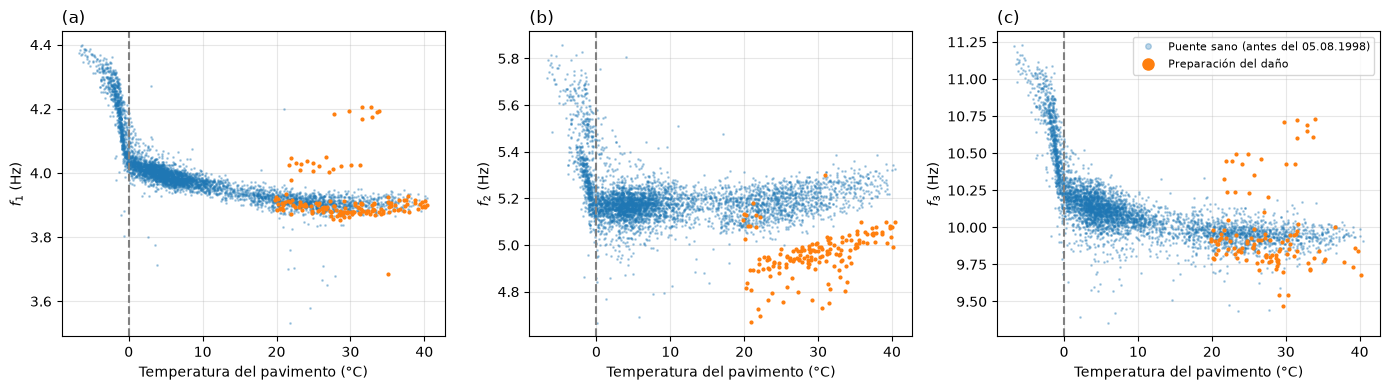

**Figura 4.** Mediciones de la preparación del daño (naranja, 05.08.1998 al 11.08.1998, 13:15) frente a las del puente sano anteriores (azul): (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.

In [8]:
# Healthy bridge before the preparation (training + healthy test) and measurements of the preparation
healthy = data[(data["block"] == "Entrenamiento") | (data["block"] == "Prueba, puente sano")]
preparation = data[data["block"] == "Preparación del daño"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for i, mode in enumerate([1, 2, 3]):
    axes[i].plot(healthy["T"], healthy[f"f{mode}"], ".", markersize=2, alpha=0.3, color="tab:blue",
                 label="Puente sano (antes del 05.08.1998)")
    axes[i].plot(preparation["T"], preparation[f"f{mode}"], ".", markersize=4, color="tab:orange",
                 label="Preparación del daño")
    axes[i].axvline(0, color="gray", linestyle="--")     # 0 °C
    axes[i].set_xlabel("Temperatura del pavimento (°C)")
    axes[i].set_ylabel(f"$f_{mode}$ (Hz)")
    axes[i].set_title(PANEL_LABELS[i], loc="left")
    axes[i].grid(alpha=0.3)

axes[2].legend(markerscale=4, fontsize=8, loc="upper right")
fig.tight_layout()
show_figure(fig, 4, "Mediciones de la preparación del daño (naranja, 05.08.1998 al 11.08.1998, 13:15) frente a las "
            "del puente sano anteriores (azul): (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.")

- **Modo 2 (Figura 4b):** las mediciones de la preparación quedan por debajo de la nube del puente sano a la misma temperatura. Cortar la pila y poner el sistema de gatos ya cambió la rigidez del puente.
- **Modos 1 y 3:** casi todas caen dentro de la nube del puente sano, salvo unas horas con valores anormalmente altos.
- Si se usaran como puente sano, el modelo aprendería un $f_2$ más bajo de lo normal. Si se usaran como puente dañado, se contaría como "daño detectado" un cambio que no es daño. Por eso se excluyen.

In [9]:
# 1. All measurements start as valid
data["status"] = "Válida"

# 2. Measurements without some frequency or without temperature
incomplete = data["f1"].isna() | data["f2"].isna() | data["f3"].isna() | data["T"].isna()
data.loc[incomplete, "status"] = "Frecuencia o temperatura vacía"

# 3. Measurements of the damage preparation (excluded from the whole project)
data.loc[data["block"] == "Preparación del daño", "status"] = "Preparación del daño"

# Table: number of measurements of each status in each block
rows = []
for block in BLOCK_COLORS:
    block_data = data[data["block"] == block]
    rows.append({
        "Bloque": block,
        "Mediciones": len(block_data),
        "Excluidas*": (block_data["status"] != "Válida").sum(),
        "Válidas": (block_data["status"] == "Válida").sum(),
    })
status_table = pd.DataFrame(rows)

show_table(status_table, 6, "Mediciones de cada bloque según su estado.")
print(f"Valid measurements: {(data['status'] == 'Válida').sum()} of {len(data)}")

**Tabla 6.** Mediciones de cada bloque según su estado.

Bloque,Mediciones,Excluidas*,Válidas
Entrenamiento,4431,178,4253
"Prueba, puente sano",390,66,324
Preparación del daño,158,158,0
"Prueba, con daño",674,180,494


Valid measurements: 5071 of 5653


\* Las excluidas son la suma de las mediciones con alguna frecuencia o la temperatura vacía (sección 2.2) y las tomadas durante la preparación del daño (05.08.1998 al 11.08.1998, 13:15).

---
<a id="sec3"></a>
## 3. Ingeniería de variables

Se construyen las variables de entrada de la Tabla 1 a partir de la temperatura del pavimento. Se calculan con **todas** las mediciones, también las excluidas en la sección 2.5, porque su temperatura es una medición válida del ambiente.

Todas las variables usan solo la medición actual y las **anteriores**, nunca las siguientes. En el monitoreo real, cuando llega una medición, todavía no existen las de las horas siguientes.

### 3.1 Medias móviles de la temperatura

El puente tarda en calentarse y enfriarse: su rigidez no depende solo de la temperatura de este momento, sino también de la de las horas anteriores. La media móvil de $w$ horas resume esa historia:

$$
\bar{T}_{w,i} = \frac{1}{n_{w,i}} \sum_{j\,:\; t_i - w < t_j \le t_i} T_j
\tag{3}
$$

donde $T_j$ es la temperatura del pavimento de la medición $j$, $t_j$ su hora y $n_{w,i}$ el número de mediciones de las últimas $w$ horas hasta la medición $i$ (incluida). Si hay un hueco, se promedian solo las mediciones que existen dentro de la ventana. Se usan $w$ = 6, 12 y 24 h.

### 3.2 Horas seguidas bajo cero (variante A)

Cuenta cuánto tiempo lleva el pavimento bajo 0 °C sin interrupción. Se recorre la serie en orden de tiempo:

- Si la medición está bajo 0 °C y la anterior también, se suman las horas transcurridas desde la anterior.
- Si la medición está bajo 0 °C y la anterior no, empieza una helada nueva: el contador vale 0.
- Si la medición está sobre 0 °C, el contador vuelve a 0.

Si hay un hueco y las mediciones de los dos lados están bajo cero, se supone que siguió helando durante el hueco y se suman sus horas. Esto pasa en el hueco del 28 al 30.01.1998 (47 h, de −1.2 a −0.6 °C).

In [10]:
# 1. Sort all the measurements by date (needed for the moving averages and the counter)
data = data.sort_values("start").reset_index(drop=True)

# 2. Moving averages of the temperature over the last 6, 12 and 24 h (Eq. 3)
#    rolling("6h", on="start") takes, for each measurement, the measurements of the previous 6 h (itself included)
data["T_mean_6h"] = data.rolling("6h", on="start")["T"].mean()
data["T_mean_12h"] = data.rolling("12h", on="start")["T"].mean()
data["T_mean_24h"] = data.rolling("24h", on="start")["T"].mean()

# 3. Consecutive hours below 0 °C (variant A)
hours_below_zero = []
counter = 0
previous_T = np.nan
previous_start = None

for _, row in data.iterrows():
    if row["T"] < 0 and previous_T < 0:
        # Still freezing: add the hours since the previous measurement
        counter = counter + (row["start"] - previous_start).total_seconds() / 3600
    else:
        # Above 0 °C, or the first measurement of a new frost: start again from 0
        counter = 0
    hours_below_zero.append(counter)
    previous_T = row["T"]
    previous_start = row["start"]

data["hours_below_zero"] = hours_below_zero

print(f"Longest frost: {data['hours_below_zero'].max():.0f} h, until {data.loc[data['hours_below_zero'].idxmax(), 'start']}")
print(f"Measurements below 0 °C: {(data['T'] < 0).sum()}")

Longest frost: 206 h, until 1998-01-30 15:00:11
Measurements below 0 °C: 799


La Figura 5 muestra las variables nuevas en el invierno, junto con $f_1$.

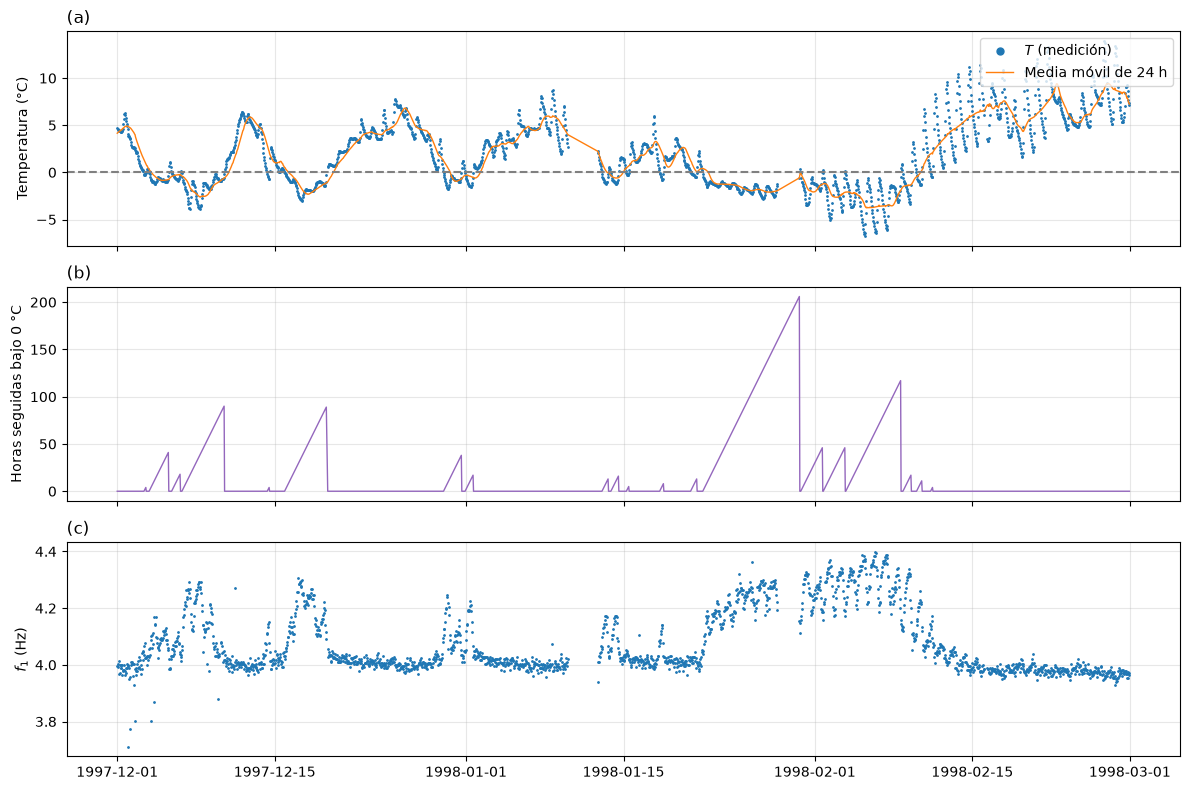

**Figura 5.** Variables de entrada en el invierno (01.12.1997 al 28.02.1998): (a) temperatura del pavimento y su media móvil de 24 h (Ec. 3), (b) horas seguidas bajo 0 °C y (c) frecuencia del modo 1. La línea discontinua de (a) marca 0 °C.

In [11]:
# Winter only: from 01.12.1997 to 28.02.1998
winter = data[(data["start"] >= "1997-12-01") & (data["start"] < "1998-03-01")]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

# (a) Temperature and its 24 h moving average
axes[0].plot(winter["start"], winter["T"], ".", markersize=2, color="tab:blue", label="$T$ (medición)")
axes[0].plot(winter["start"], winter["T_mean_24h"], "-", linewidth=1, color="tab:orange", label="Media móvil de 24 h")
axes[0].axhline(0, color="gray", linestyle="--")        # 0 °C
axes[0].set_ylabel("Temperatura (°C)")
axes[0].set_title("(a)", loc="left")
axes[0].legend(markerscale=5, loc="upper right")
axes[0].grid(alpha=0.3)

# (b) Consecutive hours below 0 °C
axes[1].plot(winter["start"], winter["hours_below_zero"], "-", linewidth=1, color="tab:purple")
axes[1].set_ylabel("Horas seguidas bajo 0 °C")
axes[1].set_title("(b)", loc="left")
axes[1].grid(alpha=0.3)

# (c) Natural frequency of mode 1
axes[2].plot(winter["start"], winter["f1"], ".", markersize=2, color="tab:blue")
axes[2].set_ylabel("$f_1$ (Hz)")
axes[2].set_title("(c)", loc="left")
axes[2].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 5, "Variables de entrada en el invierno (01.12.1997 al 28.02.1998): (a) temperatura del pavimento "
            "y su media móvil de 24 h (Ec. 3), (b) horas seguidas bajo 0 °C y (c) frecuencia del modo 1. La línea "
            "discontinua de (a) marca 0 °C.")

- La media móvil de 24 h (Figura 5a) sigue a la temperatura con retraso y sin la oscilación del día y la noche.
- La helada más larga dura 206 h (unos 8.5 días) y termina el 30.01.1998 (Figura 5b). Durante ella $f_1$ sube de 4.0 a 4.3 Hz (Figura 5c): cuanto más dura la helada, más sube la frecuencia.
- **Debilidad de la variante A:** el contador vuelve a 0 en cuanto la temperatura pasa de 0 °C, aunque sea una hora. Del 30.01 al 10.02.1998 el contador se reinicia varias veces, pero $f_1$ sigue en 4.2–4.4 Hz: el asfalto sigue congelado aunque el aire del pavimento pase un rato de 0 °C. La variante B (grados-hora de helada, Tabla 1) busca corregir esto.

### 3.3 ¿Aportan información las variables nuevas?

La Figura 6 repite la Figura 3 solo para temperaturas bajo 3 °C, con cada punto coloreado según las horas seguidas bajo cero. Se usan las mediciones válidas del entrenamiento.

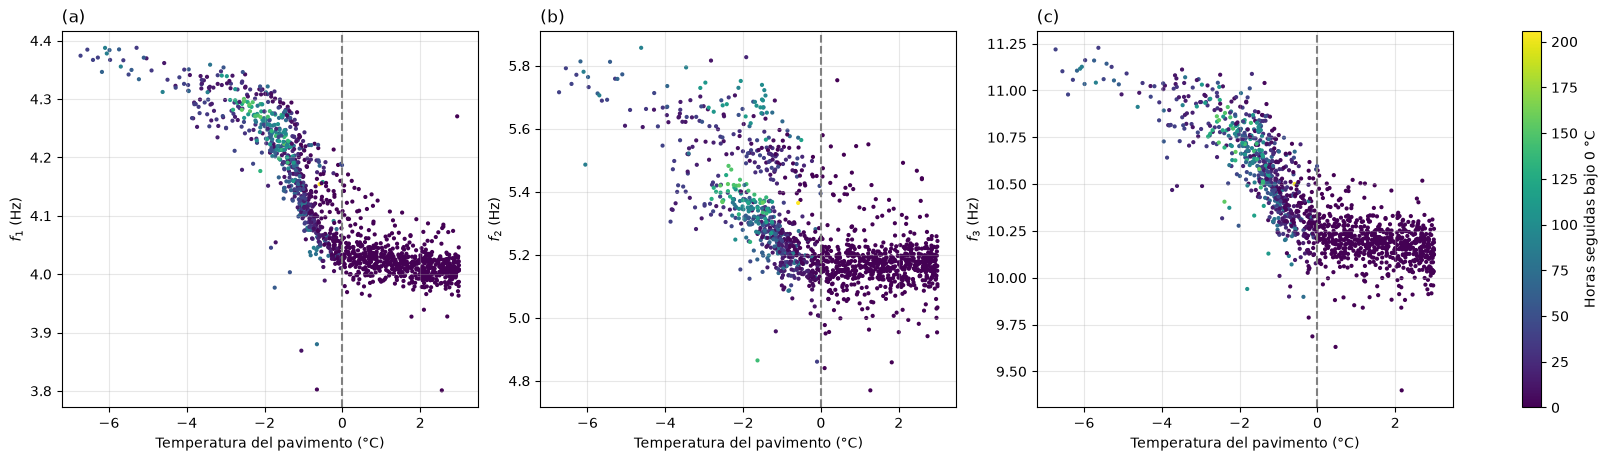

**Figura 6.** Frecuencia natural frente a la temperatura del pavimento bajo 3 °C (mediciones válidas del entrenamiento), con el color según las horas seguidas bajo 0 °C: (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.

In [12]:
# Valid measurements of the training block, with T below 3 °C
training_valid = data[(data["block"] == "Entrenamiento") & (data["status"] == "Válida")]
cold = training_valid[training_valid["T"] < 3]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")

for i, mode in enumerate([1, 2, 3]):
    points = axes[i].scatter(cold["T"], cold[f"f{mode}"], c=cold["hours_below_zero"], s=4, cmap="viridis")
    axes[i].axvline(0, color="gray", linestyle="--")     # 0 °C
    axes[i].set_xlabel("Temperatura del pavimento (°C)")
    axes[i].set_ylabel(f"$f_{mode}$ (Hz)")
    axes[i].set_title(PANEL_LABELS[i], loc="left")
    axes[i].grid(alpha=0.3)

fig.colorbar(points, ax=axes, label="Horas seguidas bajo 0 °C")
show_figure(fig, 6, "Frecuencia natural frente a la temperatura del pavimento bajo 3 °C (mediciones válidas del "
            "entrenamiento), con el color según las horas seguidas bajo 0 °C: (a) modo 1, (b) modo 2 y (c) modo 3. "
            "La línea discontinua marca 0 °C.")

- **Modos 1 y 3:** entre −3 y −1 °C, los puntos con más horas bajo cero (verde) quedan arriba, con las frecuencias más altas. A la misma temperatura, una helada más larga rigidiza más el puente: la variable sí aporta información que la temperatura sola no tiene.
- **Modo 2:** no se ve esa tendencia; hay frecuencias altas también con pocas horas bajo cero.
- **Sobre 0 °C** hay puntos con frecuencias altas (por ejemplo, $f_1$ de 4.1–4.2 Hz) y contador en 0: son deshielos, en que el asfalto sigue congelado. La variante A no los distingue.

La Tabla 7 resume la relación de cada variable con cada frecuencia con el coeficiente de correlación de Pearson:

$$
r = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2}\,\sqrt{\sum_{i=1}^{n} (y_i - \bar{y})^2}}
\tag{4}
$$

donde $x_i$ es la variable de entrada en la medición $i$, $y_i$ la frecuencia, $\bar{x}$ e $\bar{y}$ sus medias y $n$ el número de mediciones. Va de −1 a 1 y solo mide qué tan bien se alinean los puntos en una recta: una relación fuerte pero curva puede dar un $r$ bajo.

In [13]:
FEATURES = ["T", "T_mean_6h", "T_mean_12h", "T_mean_24h", "hours_below_zero"]

# Pearson correlation (Eq. 4) of each input variable with each frequency
rows = []
for feature in FEATURES:
    rows.append({
        "Variable": feature,
        "r con f1": training_valid[feature].corr(training_valid["f1"]),
        "r con f2": training_valid[feature].corr(training_valid["f2"]),
        "r con f3": training_valid[feature].corr(training_valid["f3"]),
    })
correlation_table = pd.DataFrame(rows)

show_table(correlation_table, 7, "Coeficiente de correlación de Pearson (Ec. 4) de cada variable de entrada con cada "
           "frecuencia (mediciones válidas del entrenamiento).")

**Tabla 7.** Coeficiente de correlación de Pearson (Ec. 4) de cada variable de entrada con cada frecuencia (mediciones válidas del entrenamiento).

Variable,r con f1,r con f2,r con f3
T,-0.71,-0.16,-0.64
T_mean_6h,-0.71,-0.15,-0.64
T_mean_12h,-0.71,-0.16,-0.64
T_mean_24h,-0.71,-0.18,-0.65
hours_below_zero,0.65,0.47,0.61


- La temperatura y sus tres medias móviles dan casi el mismo $r$: están muy correlacionadas entre sí (colinealidad). En una relación lineal no se aportan nada unas a otras; si ayudan, será en los modelos no lineales, y se comprueba en la sección de modelos comparando con y sin ellas.
- Las horas bajo cero son la variable más relacionada con $f_2$ ($r$ = 0.47, contra −0.16 de la temperatura): sobre 0 °C $f_2$ casi no cambia, y lo que la mueve es la helada.
- Para $f_1$ y $f_3$ la temperatura tiene un $r$ algo mayor que las horas bajo cero, pero las dos variables explican partes distintas: la temperatura, la tendencia de todo el año; las horas bajo cero, la subida durante las heladas.

---
<a id="sec4"></a>
## 4. Primer modelo: regresión lineal

Se empieza por el modelo más simple, para tener una referencia con la que comparar los modelos más complejos.

### 4.1 Modelos

Se entrena un modelo por modo ($f_1$, $f_2$ y $f_3$), con las cinco variables de entrada de la sección 3 (variante A del tiempo bajo cero):

$$
\mathbf{x}_i = \left[\, T_i,\ \bar{T}_{6,i},\ \bar{T}_{12,i},\ \bar{T}_{24,i},\ h_i \,\right]
$$

donde $T_i$ es la temperatura del pavimento, $\bar{T}_{w,i}$ sus medias móviles de $w$ horas (Ec. 3) y $h_i$ las horas seguidas bajo 0 °C.

**Referencia trivial (media).** Predice siempre la frecuencia media del entrenamiento, sin mirar la temperatura. Es lo que se tendría sin corregir por temperatura. Un modelo útil tiene que ser claramente mejor que ella.

**Regresión lineal.** La frecuencia es una suma ponderada de las variables de entrada:

$$
\hat{f}_m(\mathbf{x}_i) = \beta_0 + \beta_1 T_i + \beta_2 \bar{T}_{6,i} + \beta_3 \bar{T}_{12,i} + \beta_4 \bar{T}_{24,i} + \beta_5 h_i
\tag{5}
$$

donde $\beta_0$ es la constante y $\beta_1, \dots, \beta_5$ el peso de cada variable. Los coeficientes se eligen para que la suma de los residuos al cuadrado (Ec. 1) en el entrenamiento sea la menor posible (mínimos cuadrados).

### 4.2 Validación cruzada por semanas

Se usan los folds de la sección 1.5. Para cada fold:

1. Se entrena el modelo con las mediciones válidas de los otros cuatro folds.
2. Se predicen las mediciones del fold que quedó fuera.

Al terminar, cada medición del entrenamiento tiene una predicción hecha por un modelo que no vio su semana. Con esas predicciones se calcula el error:

$$
\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} r_i^2}
\tag{6}
$$

donde $r_i$ es el residuo de la medición $i$ (Ec. 1) y $n$ el número de mediciones. Está en Hz, como la frecuencia, y se calcula también por separado bajo y sobre 0 °C.

In [14]:
# 1. Add the fold of each training measurement (Section 1.5) to the main table
data = pd.merge(data, training[["code", "fold"]], on="code", how="left")

# 2. Valid measurements of the training block
train_data = data[(data["block"] == "Entrenamiento") & (data["status"] == "Válida")].copy()

# 3. Cross-validation by weeks: for each fold, fit with the other 4 folds and predict the fold left out
for mode in [1, 2, 3]:
    target = f"f{mode}"
    train_data[f"mean_pred_f{mode}"] = np.nan
    train_data[f"linear_pred_f{mode}"] = np.nan

    for fold in [1, 2, 3, 4, 5]:
        fit_rows = train_data["fold"] != fold        # measurements used to fit the model
        val_rows = train_data["fold"] == fold        # measurements predicted (validation)

        # Trivial reference: the mean frequency of the fitting measurements
        train_data.loc[val_rows, f"mean_pred_f{mode}"] = train_data.loc[fit_rows, target].mean()

        # Linear regression (Eq. 5)
        model = LinearRegression()
        model.fit(train_data.loc[fit_rows, FEATURES], train_data.loc[fit_rows, target])
        train_data.loc[val_rows, f"linear_pred_f{mode}"] = model.predict(train_data.loc[val_rows, FEATURES])

    # Residuals: measured minus predicted (Eq. 1)
    train_data[f"mean_res_f{mode}"] = train_data[target] - train_data[f"mean_pred_f{mode}"]
    train_data[f"linear_res_f{mode}"] = train_data[target] - train_data[f"linear_pred_f{mode}"]


# 4. RMSE (Eq. 6)
def rmse(residuals):
    return np.sqrt(np.mean(residuals ** 2))


below_zero = train_data["T"] < 0

rows = []
for mode in [1, 2, 3]:
    for model_name, prefix in [("Media (referencia)", "mean"), ("Regresión lineal", "linear")]:
        residuals = train_data[f"{prefix}_res_f{mode}"]
        rows.append({
            "Modo": mode,
            "Modelo": model_name,
            "RMSE total (Hz)": rmse(residuals),
            "RMSE bajo 0 °C (Hz)": rmse(residuals[below_zero]),
            "RMSE sobre 0 °C (Hz)": rmse(residuals[~below_zero]),
        })
rmse_table = pd.DataFrame(rows)

print(f"Valid training measurements: {len(train_data)} ({below_zero.sum()} below 0 °C)")
show_table(rmse_table, 8, "RMSE (Ec. 6) de la validación cruzada por semanas: referencia trivial (media) y regresión "
           "lineal (Ec. 5), con las variables de la sección 3 (variante A).", decimals=3)

Valid training measurements: 4253 (725 below 0 °C)


**Tabla 8.** RMSE (Ec. 6) de la validación cruzada por semanas: referencia trivial (media) y regresión lineal (Ec. 5), con las variables de la sección 3 (variante A).

Modo,Modelo,RMSE total (Hz),RMSE bajo 0 °C (Hz),RMSE sobre 0 °C (Hz)
1,Media (referencia),0.099,0.203,0.058
1,Regresión lineal,0.055,0.118,0.029
2,Media (referencia),0.117,0.230,0.075
2,Regresión lineal,0.108,0.215,0.067
3,Media (referencia),0.249,0.496,0.155
3,Regresión lineal,0.162,0.315,0.106


La Figura 7 muestra, para cada medición del entrenamiento, la frecuencia medida (azul) y la que predice la regresión lineal (rojo). El error de cada medición es la distancia vertical entre su punto azul y su punto rojo.

Las predicciones no forman una línea sino una banda. El modelo no usa solo la temperatura de ese momento, sino las cinco variables de la Ec. 5. Dos mediciones con la misma temperatura pueden tener medias móviles y horas bajo cero distintas, y entonces el modelo les predice frecuencias distintas.

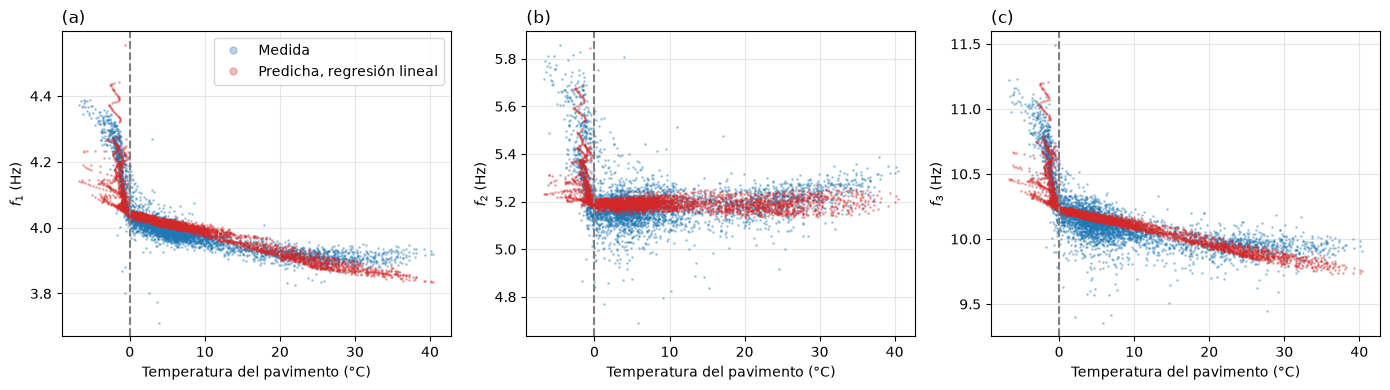

**Figura 7.** Frecuencia medida y predicha por la regresión lineal (Ec. 5) en la validación cruzada por semanas, frente a la temperatura del pavimento: (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for i, mode in enumerate([1, 2, 3]):
    axes[i].plot(train_data["T"], train_data[f"f{mode}"], ".", markersize=2, alpha=0.3, color="tab:blue",
                 label="Medida")
    axes[i].plot(train_data["T"], train_data[f"linear_pred_f{mode}"], ".", markersize=2, alpha=0.3, color="tab:red",
                 label="Predicha, regresión lineal")
    axes[i].axvline(0, color="gray", linestyle="--")     # 0 °C
    axes[i].set_xlabel("Temperatura del pavimento (°C)")
    axes[i].set_ylabel(f"$f_{mode}$ (Hz)")
    axes[i].set_title(PANEL_LABELS[i], loc="left")
    axes[i].grid(alpha=0.3)

axes[0].legend(markerscale=5, loc="upper right")
fig.tight_layout()
show_figure(fig, 7, "Frecuencia medida y predicha por la regresión lineal (Ec. 5) en la validación cruzada por "
            "semanas, frente a la temperatura del pavimento: (a) modo 1, (b) modo 2 y (c) modo 3. La línea "
            "discontinua marca 0 °C.")

La Figura 8 muestra los residuos de la regresión lineal frente a la temperatura. Si el modelo fuera bueno, los residuos estarían centrados en 0 a cualquier temperatura.

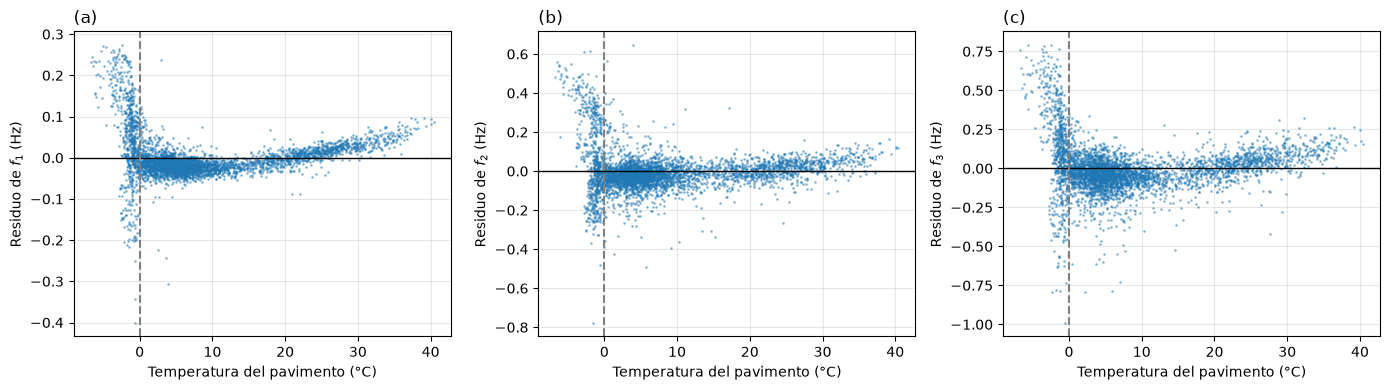

**Figura 8.** Residuos (Ec. 1) de la regresión lineal en la validación cruzada por semanas, frente a la temperatura del pavimento: (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for i, mode in enumerate([1, 2, 3]):
    axes[i].plot(train_data["T"], train_data[f"linear_res_f{mode}"], ".", markersize=2, alpha=0.4)
    axes[i].axhline(0, color="black", linewidth=1)
    axes[i].axvline(0, color="gray", linestyle="--")     # 0 °C
    axes[i].set_xlabel("Temperatura del pavimento (°C)")
    axes[i].set_ylabel(f"Residuo de $f_{mode}$ (Hz)")
    axes[i].set_title(PANEL_LABELS[i], loc="left")
    axes[i].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 8, "Residuos (Ec. 1) de la regresión lineal en la validación cruzada por semanas, frente a la "
            "temperatura del pavimento: (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.")

**Resultados de la Tabla 8:**

- La regresión lineal mejora a la referencia en los tres modos, sobre todo en $f_1$ (de 0.099 a 0.055 Hz) y $f_3$ (de 0.249 a 0.162 Hz). En $f_2$ casi no mejora (de 0.117 a 0.108 Hz): sobre 0 °C $f_2$ casi no depende de la temperatura, y la helada la mueve de forma no lineal.
- **Bajo 0 °C el error es unas 4 veces mayor que sobre 0 °C** en los tres modos (por ejemplo, 0.118 contra 0.029 Hz en $f_1$).

**Predicciones (Figura 7):**

- Sobre 0 °C, la banda roja sigue a la nube azul, pero recta: sobre 30 °C predice demasiado bajo y entre 0 y 10 °C un poco alto.
- Cerca de 0 °C aparecen trazos rojos casi verticales: con la temperatura casi igual, la predicción sube a medida que aumentan las horas seguidas bajo cero.
- Bajo −2 °C la predicción baja (4.1–4.2 Hz en $f_1$) mientras la medida sube (4.3–4.4 Hz): en las heladas más frías el modelo se equivoca de dirección.

**Residuos (Figura 8):**

- No están centrados en 0: tienen forma. Bajo 0 °C van de −0.4 a +0.3 Hz en $f_1$; el modelo predice demasiado alto al empezar la helada y demasiado bajo en las heladas más frías.
- Sobre 0 °C también hay una curva suave: residuos negativos entre 0 y 15 °C y positivos sobre 25 °C. La relación con la temperatura tampoco es una recta sobre 0 °C.
- Una suma ponderada de las variables (Ec. 5) no puede seguir el cambio de pendiente en 0 °C ni estas curvas. Hace falta un modelo no lineal.

Como referencia, el modelo bilineal de `z24_modal_distributions.ipynb` (Tabla 5 de ese notebook) da para $f_1$ un RMSE de 0.068 Hz bajo 0 °C y 0.029 Hz sobre 0 °C. Ese RMSE está calculado con los mismos datos del ajuste, así que es más optimista que el de la validación cruzada, pero muestra que un quiebre en 0 °C ya reduce mucho el error bajo cero.

---
<a id="sec5"></a>
## 5. Modelo no lineal: random forest

### 5.1 Qué es

**Árbol de decisión.** Divide los datos con preguntas sucesivas sobre las variables de entrada, por ejemplo "¿$T < 0.2$ °C?" y después "¿$h > 40$ h?". Cada pregunta separa las mediciones en dos grupos, y se elige la que deja grupos con frecuencias lo más parecidas posible. Al final, cada grupo (hoja) predice la frecuencia media de sus mediciones de entrenamiento. Así, el árbol puede representar un quiebre en 0 °C o una curva sin que nadie le diga dónde están.

**Random forest** (bosque aleatorio). Un solo árbol se ajusta demasiado a los datos de entrenamiento (sobreajuste). El random forest entrena muchos árboles distintos y promedia sus predicciones:

$$
\hat{f}_m(\mathbf{x}_i) = \frac{1}{B} \sum_{b=1}^{B} \hat{f}_m^{(b)}(\mathbf{x}_i)
\tag{7}
$$

donde $B$ es el número de árboles y $\hat{f}_m^{(b)}$ la predicción del árbol $b$. Los árboles son distintos porque cada uno se entrena con una muestra al azar de las mediciones (con reemplazo) y, en cada pregunta, solo mira una parte de las variables. Al promediar, los errores de cada árbol se compensan.

**Hiperparámetros usados** (se eligen antes de entrenar, no los aprende el modelo):

- `n_estimators = 200`: número de árboles $B$.
- `min_samples_leaf = 5`: cada hoja tiene al menos 5 mediciones. Evita hojas con una sola medición, que copiarían el ruido.
- `random_state = 42`: semilla fija, para que el resultado sea siempre el mismo.

Son valores habituales; en la sección siguiente se ajustan con la validación cruzada.

**Por qué este modelo:** capta relaciones no lineales sin tener que definir su forma, no necesita escalar las variables y es fácil de explicar. Su principal limitación es que **no extrapola**: fuera del rango del entrenamiento predice el valor de la hoja más cercana. Por eso le cuesta más la semana más fría (fold 3).

### 5.2 Validación cruzada por semanas

Mismo procedimiento que en la sección 4.2, con los mismos folds.

In [17]:
# Cross-validation by weeks: for each fold, fit with the other 4 folds and predict the fold left out
for mode in [1, 2, 3]:
    target = f"f{mode}"
    train_data[f"forest_pred_f{mode}"] = np.nan

    for fold in [1, 2, 3, 4, 5]:
        fit_rows = train_data["fold"] != fold        # measurements used to fit the model
        val_rows = train_data["fold"] == fold        # measurements predicted (validation)

        model = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42)
        model.fit(train_data.loc[fit_rows, FEATURES], train_data.loc[fit_rows, target])
        train_data.loc[val_rows, f"forest_pred_f{mode}"] = model.predict(train_data.loc[val_rows, FEATURES])

    # Residuals: measured minus predicted (Eq. 1)
    train_data[f"forest_res_f{mode}"] = train_data[target] - train_data[f"forest_pred_f{mode}"]

# RMSE (Eq. 6) of the three models
rows = []
for mode in [1, 2, 3]:
    for model_name, prefix in [("Media (referencia)", "mean"), ("Regresión lineal", "linear"), ("Random forest", "forest")]:
        residuals = train_data[f"{prefix}_res_f{mode}"]
        rows.append({
            "Modo": mode,
            "Modelo": model_name,
            "RMSE total (Hz)": rmse(residuals),
            "RMSE bajo 0 °C (Hz)": rmse(residuals[below_zero]),
            "RMSE sobre 0 °C (Hz)": rmse(residuals[~below_zero]),
        })
rmse_table = pd.DataFrame(rows)

show_table(rmse_table, 9, "RMSE (Ec. 6) de la validación cruzada por semanas: referencia trivial, regresión lineal "
           "(Ec. 5) y random forest (Ec. 7), con las variables de la sección 3 (variante A).", decimals=3)

**Tabla 9.** RMSE (Ec. 6) de la validación cruzada por semanas: referencia trivial, regresión lineal (Ec. 5) y random forest (Ec. 7), con las variables de la sección 3 (variante A).

Modo,Modelo,RMSE total (Hz),RMSE bajo 0 °C (Hz),RMSE sobre 0 °C (Hz)
1,Media (referencia),0.099,0.203,0.058
1,Regresión lineal,0.055,0.118,0.029
1,Random forest,0.029,0.054,0.020
2,Media (referencia),0.117,0.230,0.075
2,Regresión lineal,0.108,0.215,0.067
2,Random forest,0.090,0.160,0.066
3,Media (referencia),0.249,0.496,0.155
3,Regresión lineal,0.162,0.315,0.106
3,Random forest,0.107,0.153,0.095


La Figura 9 compara los residuos del random forest con los de la regresión lineal (Figura 8).

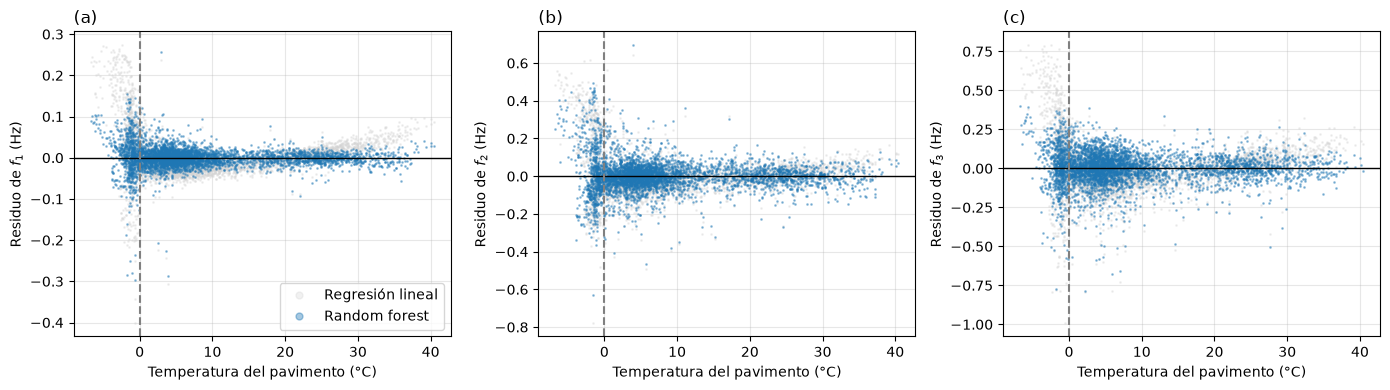

**Figura 9.** Residuos (Ec. 1) del random forest (azul) y de la regresión lineal (gris) en la validación cruzada por semanas, frente a la temperatura del pavimento: (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for i, mode in enumerate([1, 2, 3]):
    axes[i].plot(train_data["T"], train_data[f"linear_res_f{mode}"], ".", markersize=2, alpha=0.3, color="lightgray",
                 label="Regresión lineal")
    axes[i].plot(train_data["T"], train_data[f"forest_res_f{mode}"], ".", markersize=2, alpha=0.4, color="tab:blue",
                 label="Random forest")
    axes[i].axhline(0, color="black", linewidth=1)
    axes[i].axvline(0, color="gray", linestyle="--")     # 0 °C
    axes[i].set_xlabel("Temperatura del pavimento (°C)")
    axes[i].set_ylabel(f"Residuo de $f_{mode}$ (Hz)")
    axes[i].set_title(PANEL_LABELS[i], loc="left")
    axes[i].grid(alpha=0.3)

axes[0].legend(markerscale=5, loc="lower right")
fig.tight_layout()
show_figure(fig, 9, "Residuos (Ec. 1) del random forest (azul) y de la regresión lineal (gris) en la validación "
            "cruzada por semanas, frente a la temperatura del pavimento: (a) modo 1, (b) modo 2 y (c) modo 3. La "
            "línea discontinua marca 0 °C.")

La Figura 10 muestra cómo sigue el random forest a $f_1$ durante el invierno. Cada predicción la hizo un modelo que no vio esa semana.

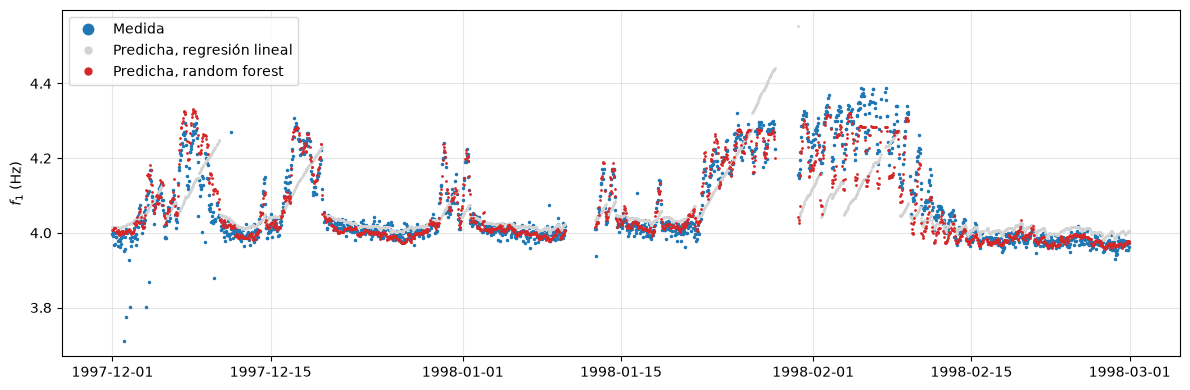

**Figura 10.** Frecuencia del modo 1 medida y predicha en la validación cruzada por semanas, en el invierno (01.12.1997 al 28.02.1998).

In [19]:
# Winter only: from 01.12.1997 to 28.02.1998
winter_train = train_data[(train_data["start"] >= "1997-12-01") & (train_data["start"] < "1998-03-01")]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(winter_train["start"], winter_train["f1"], ".", markersize=3, color="tab:blue", label="Medida")
ax.plot(winter_train["start"], winter_train["linear_pred_f1"], ".", markersize=2, color="lightgray",
        label="Predicha, regresión lineal")
ax.plot(winter_train["start"], winter_train["forest_pred_f1"], ".", markersize=2, color="tab:red",
        label="Predicha, random forest")
ax.set_ylabel("$f_1$ (Hz)")
ax.legend(markerscale=5, loc="upper left")
ax.grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 10, "Frecuencia del modo 1 medida y predicha en la validación cruzada por semanas, en el invierno "
            "(01.12.1997 al 28.02.1998).")

**Resultados (Tabla 9):**

- El random forest es el mejor en los tres modos. En $f_1$ reduce el RMSE a la mitad respecto a la regresión lineal (de 0.055 a 0.029 Hz), y bajo 0 °C de 0.118 a 0.054 Hz. Bajo 0 °C es incluso mejor que el bilineal de `z24_modal_distributions.ipynb` (0.068 Hz), y eso que aquí cada semana se predice sin haberla visto.
- En $f_3$ baja de 0.162 a 0.107 Hz. En $f_2$ mejora menos (de 0.108 a 0.090 Hz): sigue siendo el modo más difícil de predecir con la temperatura.
- Sobre 0 °C la mejora es pequeña en $f_2$ y $f_3$: ahí el error que queda es sobre todo ruido de la identificación, no algo que la temperatura explique.

**Residuos (Figura 9):** ya no tienen la forma de la regresión lineal; están centrados en 0 a todas las temperaturas. La dispersión sigue siendo mayor cerca de 0 °C y bajo cero.

**Invierno (Figura 10):**

- El random forest sigue las subidas de $f_1$ en cada helada; la regresión lineal sube en rampa con el contador de horas bajo cero y se pasa o se queda corta.
- Donde más falla es del 01 al 09.02.1998: predice 4.15–4.3 Hz y la medida llega a 4.38 Hz. Es la semana más fría (fold 3), que el modelo no vio, y además el contador de la variante A se reinicia varias veces aunque el puente sigue congelado (sección 3.2).
- Las mediciones sueltas muy bajas (por ejemplo, 3.7–3.8 Hz a comienzos de diciembre) no se predicen: son errores de identificación y quedan como residuos grandes, como se decidió en la sección 2.4.

---
<a id="sec6"></a>
## 6. Ajuste de hiperparámetros del random forest

### 6.1 Qué se ajusta

En la sección 5 se usaron valores habituales de los hiperparámetros. Aquí se eligen con la validación cruzada por semanas: se prueba cada combinación y se queda la de menor RMSE (Ec. 6). La prueba con el puente sano no se usa; queda intacta para la evaluación final.

Se ajustan dos hiperparámetros:

- **`min_samples_leaf`**: número mínimo de mediciones en cada hoja del árbol. Con valores pequeños, el árbol sigue cada detalle del entrenamiento y puede copiar el ruido de la identificación. Con valores grandes, las predicciones quedan demasiado suaves y no siguen las subidas de la helada. Se prueba 1, 5, 10, 20 y 50.
- **`max_features`**: cuántas de las cinco variables mira el árbol, elegidas al azar, en cada pregunta. Con 5 mira todas (es lo que se usó en la sección 5). Con menos, los árboles son más distintos entre sí y al promediarlos (Ec. 7) sus errores se compensan mejor, pero cada pregunta puede no usar la variable más útil. Se prueba de 1 a 5.

Son 5 × 5 = 25 combinaciones por modo, y cada una se entrena 5 veces (una por fold). El número de árboles (`n_estimators`) se fija en 200 y se comprueba al final (sección 6.3).

In [20]:
# Cross-validation by weeks of a random forest with the given hyperparameters.
# Returns the out-of-fold prediction of every training measurement.
def forest_cv_predictions(mode, min_samples_leaf, max_features, n_estimators=200):
    target = f"f{mode}"
    predictions = pd.Series(np.nan, index=train_data.index)

    for fold in [1, 2, 3, 4, 5]:
        fit_rows = train_data["fold"] != fold        # measurements used to fit the model
        val_rows = train_data["fold"] == fold        # measurements predicted (validation)

        model = RandomForestRegressor(n_estimators=n_estimators, min_samples_leaf=min_samples_leaf,
                                      max_features=max_features, random_state=42, n_jobs=-1)
        model.fit(train_data.loc[fit_rows, FEATURES], train_data.loc[fit_rows, target])
        predictions[val_rows] = model.predict(train_data.loc[val_rows, FEATURES])

    return predictions


LEAF_VALUES = [1, 5, 10, 20, 50]          # values of min_samples_leaf
MAX_FEATURES_VALUES = [1, 2, 3, 4, 5]     # values of max_features

# Try every combination for every mode and keep its RMSE (Eq. 6)
rows = []
for mode in [1, 2, 3]:
    for min_samples_leaf in LEAF_VALUES:
        for max_features in MAX_FEATURES_VALUES:
            predictions = forest_cv_predictions(mode, min_samples_leaf, max_features)
            residuals = train_data[f"f{mode}"] - predictions
            rows.append({
                "Modo": mode,
                "min_samples_leaf": min_samples_leaf,
                "max_features": max_features,
                "RMSE total (Hz)": rmse(residuals),
            })
search_table = pd.DataFrame(rows)
print(f"Combinations tried: {len(search_table)}")

Combinations tried: 75


La Figura 11 muestra el RMSE de cada combinación.

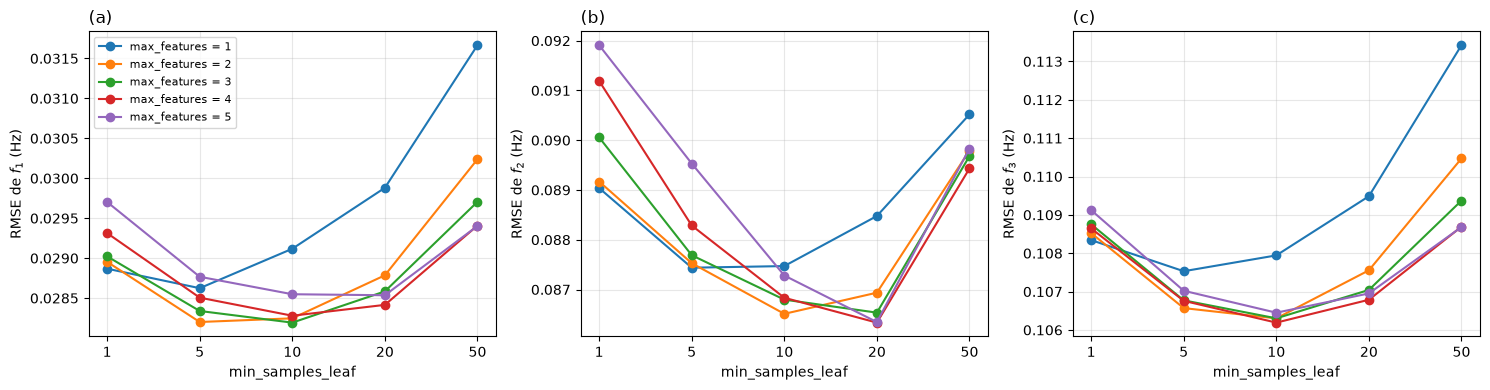

**Figura 11.** RMSE (Ec. 6) del random forest en la validación cruzada por semanas para cada combinación de min_samples_leaf y max_features: (a) modo 1, (b) modo 2 y (c) modo 3.

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, mode in enumerate([1, 2, 3]):
    mode_results = search_table[search_table["Modo"] == mode]

    # One line for each value of max_features
    for max_features in MAX_FEATURES_VALUES:
        line = mode_results[mode_results["max_features"] == max_features]
        axes[i].plot(range(len(LEAF_VALUES)), line["RMSE total (Hz)"], "o-", label=f"max_features = {max_features}")

    axes[i].set_xticks(range(len(LEAF_VALUES)))
    axes[i].set_xticklabels(LEAF_VALUES)
    axes[i].set_xlabel("min_samples_leaf")
    axes[i].set_ylabel(f"RMSE de $f_{mode}$ (Hz)")
    axes[i].set_title(PANEL_LABELS[i], loc="left")
    axes[i].grid(alpha=0.3)

axes[0].legend(fontsize=8)
fig.tight_layout()
show_figure(fig, 11, "RMSE (Ec. 6) del random forest en la validación cruzada por semanas para cada combinación de "
            "min_samples_leaf y max_features: (a) modo 1, (b) modo 2 y (c) modo 3.")

### 6.2 Combinación elegida

Para cada modo se elige la combinación de menor RMSE total. La Tabla 10 la compara con el random forest de la sección 5 (`min_samples_leaf = 5`, `max_features = 5`).

In [22]:
# 1. Best combination of each mode (lowest total RMSE)
BEST_PARAMS = {}
for mode in [1, 2, 3]:
    mode_results = search_table[search_table["Modo"] == mode]
    best_row = mode_results.loc[mode_results["RMSE total (Hz)"].idxmin()]
    BEST_PARAMS[mode] = {
        "min_samples_leaf": int(best_row["min_samples_leaf"]),
        "max_features": int(best_row["max_features"]),
    }
print(BEST_PARAMS)

# 2. Out-of-fold predictions and residuals (Eq. 1) of the tuned random forest
for mode in [1, 2, 3]:
    train_data[f"tuned_pred_f{mode}"] = forest_cv_predictions(mode, BEST_PARAMS[mode]["min_samples_leaf"],
                                                              BEST_PARAMS[mode]["max_features"])
    train_data[f"tuned_res_f{mode}"] = train_data[f"f{mode}"] - train_data[f"tuned_pred_f{mode}"]

# 3. Comparison with the random forest of Section 5
rows = []
for mode in [1, 2, 3]:
    for model_name, prefix, leaf, max_features in [
        ("Random forest (sección 5)", "forest", 5, 5),
        ("Random forest ajustado", "tuned", BEST_PARAMS[mode]["min_samples_leaf"], BEST_PARAMS[mode]["max_features"]),
    ]:
        residuals = train_data[f"{prefix}_res_f{mode}"]
        rows.append({
            "Modo": mode,
            "Modelo": model_name,
            "min_samples_leaf": leaf,
            "max_features": max_features,
            "RMSE total (Hz)": rmse(residuals),
            "RMSE bajo 0 °C (Hz)": rmse(residuals[below_zero]),
            "RMSE sobre 0 °C (Hz)": rmse(residuals[~below_zero]),
        })
tuned_table = pd.DataFrame(rows)

show_table(tuned_table, 10, "RMSE (Ec. 6) de la validación cruzada por semanas del random forest de la sección 5 y "
           "del random forest con los hiperparámetros elegidos.", decimals=4)

{1: {'min_samples_leaf': 10, 'max_features': 3}, 2: {'min_samples_leaf': 20, 'max_features': 4}, 3: {'min_samples_leaf': 10, 'max_features': 4}}


**Tabla 10.** RMSE (Ec. 6) de la validación cruzada por semanas del random forest de la sección 5 y del random forest con los hiperparámetros elegidos.

Modo,Modelo,min_samples_leaf,max_features,RMSE total (Hz),RMSE bajo 0 °C (Hz),RMSE sobre 0 °C (Hz)
1,Random forest (sección 5),5,5,0.0288,0.0536,0.0202
1,Random forest ajustado,10,3,0.0282,0.0524,0.0199
2,Random forest (sección 5),5,5,0.0895,0.1600,0.0664
2,Random forest ajustado,20,4,0.0863,0.1531,0.0646
3,Random forest (sección 5),5,5,0.1070,0.1531,0.0948
3,Random forest ajustado,10,4,0.1062,0.1532,0.0937


### 6.3 Número de árboles

Más árboles nunca empeoran el random forest: solo hacen el promedio (Ec. 7) más estable y tardan más. Se comprueba que con 200 ya no cambia, usando los hiperparámetros elegidos (Tabla 11).

In [23]:
TREE_VALUES = [50, 100, 200, 500]     # values of n_estimators

rows = []
for n_estimators in TREE_VALUES:
    row = {"n_estimators": n_estimators}
    for mode in [1, 2, 3]:
        predictions = forest_cv_predictions(mode, BEST_PARAMS[mode]["min_samples_leaf"],
                                            BEST_PARAMS[mode]["max_features"], n_estimators)
        row[f"RMSE f{mode} (Hz)"] = rmse(train_data[f"f{mode}"] - predictions)
    rows.append(row)
trees_table = pd.DataFrame(rows)

show_table(trees_table, 11, "RMSE (Ec. 6) de la validación cruzada por semanas del random forest ajustado según el "
           "número de árboles.", decimals=4)

**Tabla 11.** RMSE (Ec. 6) de la validación cruzada por semanas del random forest ajustado según el número de árboles.

n_estimators,RMSE f1 (Hz),RMSE f2 (Hz),RMSE f3 (Hz)
50,0.0282,0.0863,0.1066
100,0.0282,0.0862,0.1063
200,0.0282,0.0863,0.1062
500,0.0281,0.0863,0.1062


**Resultados:**

- **Forma de las curvas (Figura 11):** el RMSE baja y después sube al aumentar `min_samples_leaf`. Con hojas de 1 medición el árbol copia el ruido; con 50, las predicciones quedan demasiado suaves. El mínimo está en 10–20 mediciones por hoja.
- **`max_features`:** mirar las 5 variables en cada pregunta (lo de la sección 5) es de lo peor con hojas pequeñas; mirar solo 1 es lo peor con hojas grandes. Los valores intermedios (2 a 4) son los mejores.
- **Combinaciones elegidas (Tabla 10):** $f_1$: 10 y 3; $f_2$: 20 y 4; $f_3$: 10 y 4.
- **La mejora es pequeña:** el RMSE baja de 0.0288 a 0.0282 Hz en $f_1$ (2 %), de 0.0895 a 0.0863 Hz en $f_2$ (4 %) y de 0.1070 a 0.1062 Hz en $f_3$ (1 %). Cerca del mínimo, varias combinaciones se diferencian en menos de 0.001 Hz. El random forest es poco sensible a sus hiperparámetros, así que la combinación exacta importa poco.
- **Número de árboles (Tabla 11):** desde 50 árboles el RMSE ya no cambia. Se mantienen 200.
- **Bajo 0 °C el error sigue siendo 2.5 a 3 veces mayor que sobre 0 °C** (por ejemplo, 0.052 contra 0.020 Hz en $f_1$). Los hiperparámetros no lo arreglan: lo que falta es información en las variables de entrada, no flexibilidad del modelo. Por eso después se prueba la variante B del tiempo bajo cero.

**Decisión:** con la variante A, el modelo es el random forest ajustado (Tabla 10), uno por modo. Sus residuos fuera del fold (`tuned_res_f1`, `tuned_res_f2`, `tuned_res_f3`) se usan en las secciones siguientes para construir el índice de daño y calibrar el límite de alarma.

---
<a id="sec7"></a>
## 7. Índice de daño: distancia de Mahalanobis

### 7.1 Modelo final y residuos de cada bloque

El modelo final es el random forest ajustado de la sección 6, uno por modo, entrenado con **todas** las mediciones válidas del entrenamiento. Con él se predicen las mediciones válidas de los dos bloques de prueba: el puente sano (15.07 al 04.08.1998) y el puente con daño (desde el 11.08.1998, 13:15). El residuo de cada medición es la Ec. 1.

En el entrenamiento no se usan los residuos del modelo final, porque ese modelo ya vio esas mediciones y sus residuos serían demasiado pequeños. Se usan los residuos fuera del fold de la sección 6 (`tuned_res_f1` a `tuned_res_f3`): cada uno viene de un modelo que no vio esa semana, igual que en la prueba el modelo no vio esas mediciones.

In [24]:
# 1. Valid measurements of the two test blocks
test_data = data[((data["block"] == "Prueba, puente sano") | (data["block"] == "Prueba, con daño"))
                 & (data["status"] == "Válida")].copy()

# 2. Final model of each mode: tuned random forest fitted with all the training measurements
for mode in [1, 2, 3]:
    model = RandomForestRegressor(n_estimators=200, min_samples_leaf=BEST_PARAMS[mode]["min_samples_leaf"],
                                  max_features=BEST_PARAMS[mode]["max_features"], random_state=42, n_jobs=-1)
    model.fit(train_data[FEATURES], train_data[f"f{mode}"])

    # Prediction and residual (Eq. 1) of the test measurements
    test_data[f"pred_f{mode}"] = model.predict(test_data[FEATURES])
    test_data[f"res_f{mode}"] = test_data[f"f{mode}"] - test_data[f"pred_f{mode}"]

# 3. Training residuals: the out-of-fold residuals of Section 6
for mode in [1, 2, 3]:
    train_data[f"res_f{mode}"] = train_data[f"tuned_res_f{mode}"]

print(f"Test measurements: {len(test_data)}")

Test measurements: 818


### 7.2 Por qué combinar los tres residuos

Se podría vigilar cada modo por separado, pero eso da tres alarmas con tres límites, y cada una suma falsas alarmas. Es mejor un solo índice por medición. Hay dos problemas para combinarlos con una suma simple:

- **Escalas distintas:** el residuo de $f_3$ es unas 4 veces más grande que el de $f_1$ (Tabla 10), solo por ruido. En una suma, $f_3$ dominaría.
- **Correlación:** los residuos de los modos se mueven juntos (Tabla 12). Por ejemplo, cuando la helada no está bien representada, los tres modos se equivocan hacia el mismo lado. Dos residuos grandes y en el mismo sentido son menos raros de lo que parecen si se miran por separado.

In [25]:
RESIDUALS = ["res_f1", "res_f2", "res_f3"]

# Pearson correlation (Eq. 4) between the residuals of the three modes in the training block
correlation_table = train_data[RESIDUALS].corr().reset_index()
correlation_table = correlation_table.rename(columns={"index": "Residuo"})

show_table(correlation_table, 12, "Correlación de Pearson (Ec. 4) entre los residuos fuera del fold de los tres "
           "modos en el bloque de entrenamiento.")

**Tabla 12.** Correlación de Pearson (Ec. 4) entre los residuos fuera del fold de los tres modos en el bloque de entrenamiento.

Residuo,res_f1,res_f2,res_f3
res_f1,1.00,0.53,0.36
res_f2,0.53,1.00,0.39
res_f3,0.36,0.39,1.00


### 7.3 Distancia de Mahalanobis

La distancia de Mahalanobis resuelve los dos problemas. Mide qué tan lejos está el vector de residuos de una medición del centro de los residuos del puente sano, en unidades de su dispersión y teniendo en cuenta la correlación:

$$
d_i = \sqrt{(\mathbf{r}_i - \boldsymbol{\mu})^{\top}\, \boldsymbol{\Sigma}^{-1}\, (\mathbf{r}_i - \boldsymbol{\mu})}
\tag{8}
$$

donde:

- $\mathbf{r}_i = [\, r_{1,i},\ r_{2,i},\ r_{3,i} \,]$ es el vector con los residuos (Ec. 1) de los tres modos en la medición $i$;
- $\boldsymbol{\mu}$ es la media de los residuos del entrenamiento (fuera del fold), uno por modo;
- $\boldsymbol{\Sigma}$ es la matriz de covarianza 3 × 3 de esos residuos: en la diagonal, la varianza de cada modo; fuera de ella, cuánto varían juntos dos modos;
- $\boldsymbol{\Sigma}^{-1}$ es su inversa.

En palabras: cada residuo se divide por la dispersión normal de su modo, y la parte que ya se explica por la correlación con los otros modos no cuenta dos veces. $d_i$ no tiene unidades. Si los residuos fueran independientes, sería la distancia de siempre medida en desviaciones estándar: $d = 3$ es "3 desviaciones del centro".

$\boldsymbol{\mu}$ y $\boldsymbol{\Sigma}$ se calculan solo con el entrenamiento y después quedan fijos para la prueba.

In [26]:
# 1. Mean and covariance of the training residuals (Eq. 8)
train_residuals = train_data[RESIDUALS].to_numpy()       # one row per measurement, one column per mode
residual_mean = train_residuals.mean(axis=0)
residual_cov = np.cov(train_residuals, rowvar=False)
residual_cov_inv = np.linalg.inv(residual_cov)

print("Mean of the residuals (Hz):", residual_mean.round(4))
print("Standard deviation of the residuals (Hz):", np.sqrt(np.diag(residual_cov)).round(4))


# 2. Mahalanobis distance (Eq. 8) of every row of a table of residuals
def mahalanobis(residuals):
    distances = []
    for r in residuals:                       # r = [r1, r2, r3] of one measurement
        difference = r - residual_mean
        distances.append(np.sqrt(difference @ residual_cov_inv @ difference))
    return distances


train_data["d"] = mahalanobis(train_data[RESIDUALS].to_numpy())
test_data["d"] = mahalanobis(test_data[RESIDUALS].to_numpy())

Mean of the residuals (Hz): [0.0009 0.0048 0.0034]
Standard deviation of the residuals (Hz): [0.0282 0.0862 0.1061]


La Figura 12 muestra los residuos de $f_1$ y $f_2$ de cada bloque. La Figura 13 muestra el índice $d$ en el tiempo.

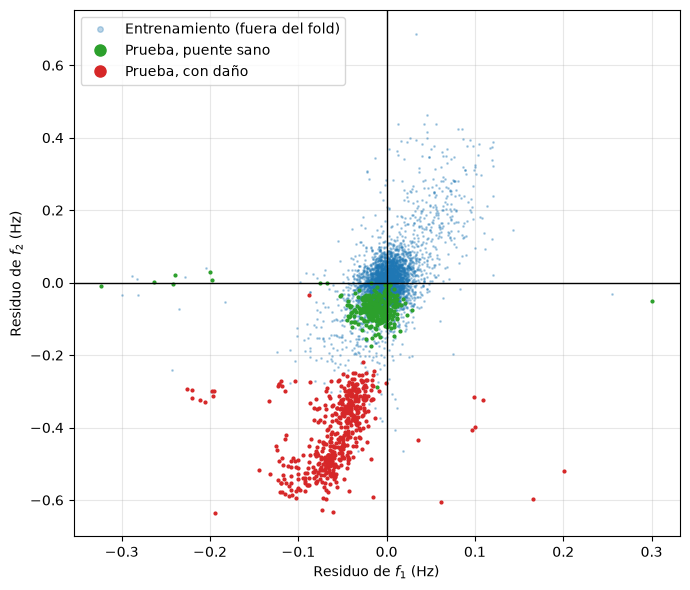

**Figura 12.** Residuos (Ec. 1) de los modos 1 y 2 en cada bloque. En el entrenamiento son los residuos fuera del fold; en la prueba, los del modelo final.

In [27]:
fig, ax = plt.subplots(figsize=(7, 6))

healthy_test = test_data[test_data["block"] == "Prueba, puente sano"]
damaged = test_data[test_data["block"] == "Prueba, con daño"]

ax.plot(train_data["res_f1"], train_data["res_f2"], ".", markersize=2, alpha=0.3,
        color=BLOCK_COLORS["Entrenamiento"], label="Entrenamiento (fuera del fold)")
ax.plot(healthy_test["res_f1"], healthy_test["res_f2"], ".", markersize=4,
        color=BLOCK_COLORS["Prueba, puente sano"], label="Prueba, puente sano")
ax.plot(damaged["res_f1"], damaged["res_f2"], ".", markersize=4,
        color=BLOCK_COLORS["Prueba, con daño"], label="Prueba, con daño")
ax.axhline(0, color="black", linewidth=1)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Residuo de $f_1$ (Hz)")
ax.set_ylabel("Residuo de $f_2$ (Hz)")
ax.legend(markerscale=4, loc="upper left")
ax.grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 12, "Residuos (Ec. 1) de los modos 1 y 2 en cada bloque. En el entrenamiento son los residuos fuera "
            "del fold; en la prueba, los del modelo final.")

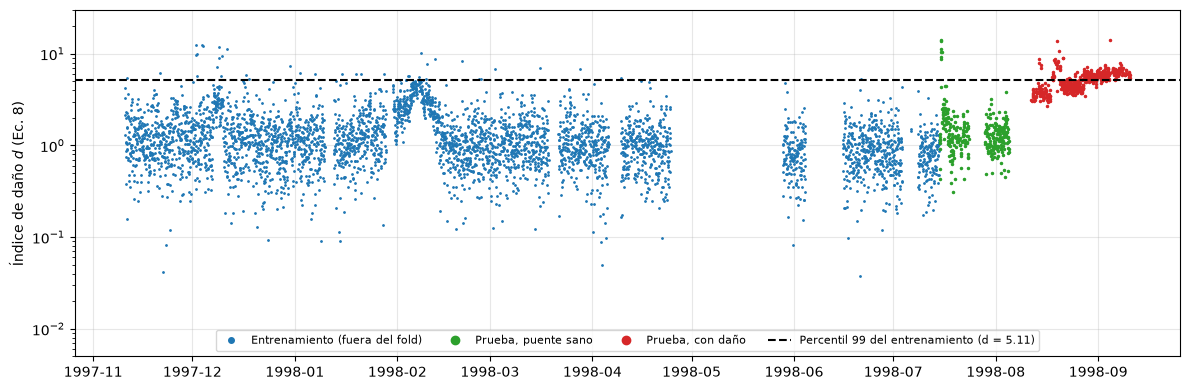

**Figura 13.** Índice de daño (distancia de Mahalanobis, Ec. 8) de cada medición válida. La línea discontinua es el percentil 99 del índice en el entrenamiento. Eje vertical en escala logarítmica.

In [28]:
# 99th percentile of the training index, only as a reference (the alarm limit is set in the next section)
d_99 = np.percentile(train_data["d"], 99)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(train_data["start"], train_data["d"], ".", markersize=2, color=BLOCK_COLORS["Entrenamiento"],
        label="Entrenamiento (fuera del fold)")
ax.plot(healthy_test["start"], healthy_test["d"], ".", markersize=3, color=BLOCK_COLORS["Prueba, puente sano"],
        label="Prueba, puente sano")
ax.plot(damaged["start"], damaged["d"], ".", markersize=3, color=BLOCK_COLORS["Prueba, con daño"],
        label="Prueba, con daño")
ax.axhline(d_99, color="black", linestyle="--", label=f"Percentil 99 del entrenamiento (d = {d_99:.2f})")
ax.set_yscale("log")
ax.set_ylim(0.005, 30)
ax.set_ylabel("Índice de daño $d$ (Ec. 8)")
ax.legend(markerscale=4, loc="lower center", ncol=4, fontsize=8)
ax.grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 13, "Índice de daño (distancia de Mahalanobis, Ec. 8) de cada medición válida. La línea discontinua "
            "es el percentil 99 del índice en el entrenamiento. Eje vertical en escala logarítmica.")

La Tabla 13 resume los residuos y el índice en cada bloque.

In [29]:
rows = []
for block, block_data in [("Entrenamiento", train_data), ("Prueba, puente sano", healthy_test),
                          ("Prueba, con daño", damaged)]:
    rows.append({
        "Bloque": block,
        "Mediciones": len(block_data),
        "Residuo medio f1 (Hz)": block_data["res_f1"].mean(),
        "Residuo medio f2 (Hz)": block_data["res_f2"].mean(),
        "Residuo medio f3 (Hz)": block_data["res_f3"].mean(),
        "Mediana de d": block_data["d"].median(),
        "% sobre el percentil 99": 100 * (block_data["d"] > d_99).mean(),
    })
index_table = pd.DataFrame(rows)

show_table(index_table, 13, "Residuo medio (Ec. 1) de cada modo, mediana del índice de daño (Ec. 8) y porcentaje "
           "de mediciones con el índice sobre el percentil 99 del entrenamiento, en cada bloque.", decimals=3)

**Tabla 13.** Residuo medio (Ec. 1) de cada modo, mediana del índice de daño (Ec. 8) y porcentaje de mediciones con el índice sobre el percentil 99 del entrenamiento, en cada bloque.

Bloque,Mediciones,Residuo medio f1 (Hz),Residuo medio f2 (Hz),Residuo medio f3 (Hz),Mediana de d,% sobre el percentil 99
Entrenamiento,4253,0.001,0.005,0.003,1.071,1.011
"Prueba, puente sano",324,-0.015,-0.071,0.014,1.274,2.160
"Prueba, con daño",494,-0.058,-0.414,-0.196,5.232,52.632


**Resultados:**

- **Correlación (Tabla 12):** los residuos de los modos están correlacionados (0.36 a 0.53). Por eso conviene la distancia de Mahalanobis y no una suma de residuos. En la Figura 12, la nube del entrenamiento está inclinada: cuando $f_1$ se predice alto, $f_2$ también.
- **Puente sano (Tabla 13):** el índice de la prueba con el puente sano es parecido al del entrenamiento (mediana 1.27 contra 1.07), y solo el 2.2 % de sus mediciones supera el percentil 99 del entrenamiento (en el entrenamiento, el 1 % por definición). El modelo final generaliza bien a semanas que no vio. Sus residuos están algo corridos hacia abajo (−0.07 Hz en $f_2$), un sesgo pequeño del verano.
- **Puente con daño (Tabla 13 y Figura 12):** los residuos se desplazan hacia abajo en los tres modos: las frecuencias medidas son menores que las que corresponden a esa temperatura en el puente sano. El cambio más grande está en $f_2$ (−0.41 Hz de media, unas 5 veces su desviación estándar), seguido de $f_3$ (−0.20 Hz) y $f_1$ (−0.06 Hz). La mediana del índice sube a 5.2 y la mitad de las mediciones (53 %) supera el percentil 99.
- **En el tiempo (Figura 13):** el índice sube desde el primer día del daño (11.08.1998), a valores de 3 a 4, y va aumentando por escalones a medida que se agravan los daños, hasta 6–7 en septiembre.
- **Valores altos en el puente sano:**
  - El 15.07.1998, entre las 08:00 y las 15:00, el índice llega a 9–14. Son 7 horas seguidas en que $f_1$ se identificó 0.2–0.3 Hz más baja de lo normal (3.6–3.7 Hz) y después vuelve. Es un error de identificación, no un cambio del puente, pero dura varias horas: la carta de control tiene que tolerarlo sin dar una falsa alarma.
  - En el entrenamiento, los valores altos se concentran en diciembre y febrero (Figura 13), en las heladas que el modelo predice peor (sección 6).

Una medición sola no basta para decidir: con el percentil 99 como límite, la mitad de las mediciones con daño quedan por debajo y algunas del puente sano quedan por encima. Por eso, en la sección siguiente el índice se suaviza con la carta de control EWMA (Ec. 2), que acumula la evidencia de varias mediciones.

---
<a id="sec8"></a>
## 8. Carta de control EWMA y límite de alarma

### 8.1 Suavizado del índice

El índice de daño $d_i$ (Ec. 8) se suaviza con la media móvil exponencial (EWMA) de la Ec. 2:

$$
z_i = \lambda\, d_i + (1 - \lambda)\, z_{i-1}
$$

- $z_i$ es una media de todas las mediciones anteriores, en la que cada medición pesa menos cuanto más vieja es: la medición de hace $k$ pasos pesa $\lambda (1-\lambda)^k$.
- Se usa $\lambda = 0.1$, un valor habitual en cartas de control (entre 0.05 y 0.25). La medición nueva pesa el 10 %, y la mitad del peso total está en las últimas 7 mediciones (unas 7 h). Así, un error de una hora casi no mueve $z$, pero un cambio que dura más de medio día sí.
- El valor inicial $z_0$ es la media de $d$ en el entrenamiento: se supone que el monitoreo empieza con el puente sano.
- Se recorre la serie medición por medición, en orden de tiempo. Si hay un hueco, se sigue con la medición siguiente.

Con el puente sano, la EWMA se calcula sobre los residuos fuera del fold del entrenamiento (sección 7.1). En la prueba se calcula sobre los dos bloques seguidos: primero el puente sano y después el puente con daño, como en un monitoreo real.

In [30]:
LAMBDA = 0.1     # weight of the new measurement in the EWMA (Eq. 2)


# EWMA (Eq. 2) of a series of damage indices, in time order
def ewma(values, lam, start_value):
    smoothed = []
    z = start_value
    for d in values:
        z = lam * d + (1 - lam) * z
        smoothed.append(z)
    return smoothed


# Both tables are already in time order (Section 3)
z_start = train_data["d"].mean()
train_data["z"] = ewma(train_data["d"], LAMBDA, z_start)
test_data["z"] = ewma(test_data["d"], LAMBDA, z_start)

print(f"Start value z0 = {z_start:.2f}")

Start value z0 = 1.36


### 8.2 Límite de alarma

Hay alarma cuando la EWMA supera el límite de control superior (UCL, *Upper Control Limit*):

$$
\text{alarma en } i \iff z_i > \text{UCL}, \qquad \text{UCL} = \max_{i \,\in\, \text{entrenamiento}} z_i
\tag{9}
$$

donde el máximo se toma sobre la EWMA del entrenamiento. Es el valor más alto que alcanzó la EWMA con el puente sano durante 8 meses, así que con ese límite **no hay ninguna falsa alarma en el entrenamiento**. Solo usa datos del puente sano; los datos con daño no intervienen.

**Un límite o dos.** En la Figura 13 el índice es más alto en las heladas, sobre todo en febrero, donde el modelo se equivoca varios días seguidos. Esos errores duran mucho, y la EWMA no los puede filtrar. Si hay un solo límite, lo fijan las heladas y queda muy alto para el resto del año. Por eso se prueba también con **dos límites**, calculados con la Ec. 9 por separado:

- **Con helada:** si hubo alguna medición bajo 0 °C en las 72 h anteriores. Se toman 72 h porque el asfalto sigue rígido un tiempo después de descongelarse y porque la EWMA arrastra el efecto unas horas más.
- **Sin helada:** el resto.

En cada medición se usa el límite que corresponde a la temperatura de las 72 h anteriores, que en el monitoreo ya se conoce.

In [31]:
# 1. Frost in the last 72 h: some measurement below 0 °C in the previous 72 h (all measurements, past only)
data["below_zero_flag"] = (data["T"] < 0).astype(float)          # 1 if below 0 °C, 0 if not
data["frost_last_72h"] = data.rolling("72h", on="start")["below_zero_flag"].max() == 1

train_data["frost_last_72h"] = data.loc[train_data.index, "frost_last_72h"]
test_data["frost_last_72h"] = data.loc[test_data.index, "frost_last_72h"]

# 2. Limits (Eq. 9): the highest EWMA of the training block
LIMIT_SINGLE = train_data["z"].max()
LIMIT_FROST = train_data.loc[train_data["frost_last_72h"], "z"].max()
LIMIT_NO_FROST = train_data.loc[~train_data["frost_last_72h"], "z"].max()

limits_table = pd.DataFrame([
    {"Límite": "Un límite (todo el entrenamiento)", "Mediciones del entrenamiento": len(train_data),
     "UCL": LIMIT_SINGLE},
    {"Límite": "Dos límites: con helada en las 72 h anteriores",
     "Mediciones del entrenamiento": train_data["frost_last_72h"].sum(), "UCL": LIMIT_FROST},
    {"Límite": "Dos límites: sin helada", "Mediciones del entrenamiento": (~train_data["frost_last_72h"]).sum(),
     "UCL": LIMIT_NO_FROST},
])
show_table(limits_table, 14, "Límites de alarma (Ec. 9) calculados con la EWMA (Ec. 2, λ = 0.1) del entrenamiento.")

# 3. Limit of each test measurement with two limits
two_limits = []
for frost in test_data["frost_last_72h"]:
    if frost:
        two_limits.append(LIMIT_FROST)
    else:
        two_limits.append(LIMIT_NO_FROST)
test_data["limit_two"] = two_limits
print(f"Test measurements with frost in the last 72 h: {test_data['frost_last_72h'].sum()}")

**Tabla 14.** Límites de alarma (Ec. 9) calculados con la EWMA (Ec. 2, λ = 0.1) del entrenamiento.

Límite,Mediciones del entrenamiento,UCL
Un límite (todo el entrenamiento),4253,5.08
Dos límites: con helada en las 72 h anteriores,1425,5.08
Dos límites: sin helada,2828,3.08


Test measurements with frost in the last 72 h: 0


La Figura 14 muestra la EWMA del entrenamiento con los límites.

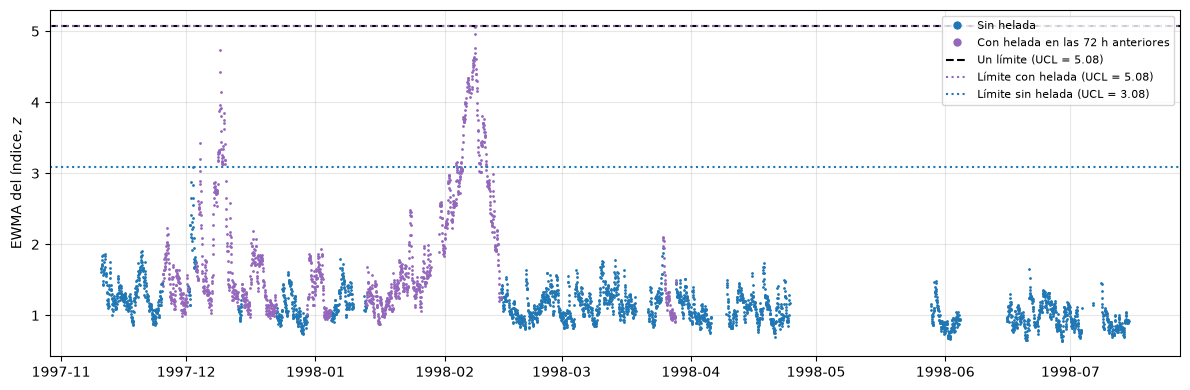

**Figura 14.** EWMA (Ec. 2, λ = 0.1) del índice de daño en el entrenamiento (residuos fuera del fold) y límites de alarma (Ec. 9).

In [32]:
frost_rows = train_data[train_data["frost_last_72h"]]
no_frost_rows = train_data[~train_data["frost_last_72h"]]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(no_frost_rows["start"], no_frost_rows["z"], ".", markersize=2, color="tab:blue", label="Sin helada")
ax.plot(frost_rows["start"], frost_rows["z"], ".", markersize=2, color="tab:purple",
        label="Con helada en las 72 h anteriores")
ax.axhline(LIMIT_SINGLE, color="black", linestyle="--", label=f"Un límite (UCL = {LIMIT_SINGLE:.2f})")
ax.axhline(LIMIT_FROST, color="tab:purple", linestyle=":", label=f"Límite con helada (UCL = {LIMIT_FROST:.2f})")
ax.axhline(LIMIT_NO_FROST, color="tab:blue", linestyle=":", label=f"Límite sin helada (UCL = {LIMIT_NO_FROST:.2f})")
ax.set_ylabel("EWMA del índice, $z$")
ax.legend(markerscale=5, loc="upper right", fontsize=8)
ax.grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 14, "EWMA (Ec. 2, λ = 0.1) del índice de daño en el entrenamiento (residuos fuera del fold) y "
            "límites de alarma (Ec. 9).")

### 8.3 Resultado en la prueba

La Figura 15 muestra la EWMA en los dos bloques de prueba. La Tabla 15 cuenta las falsas alarmas con el puente sano y el tiempo hasta detectar el daño. Una **alarma** empieza cuando $z$ pasa de estar bajo el límite a estar sobre él; si se queda sobre el límite varias horas, es la misma alarma. El **retraso de detección** son las horas desde el comienzo del daño (11.08.1998, 13:15) hasta la primera alarma.

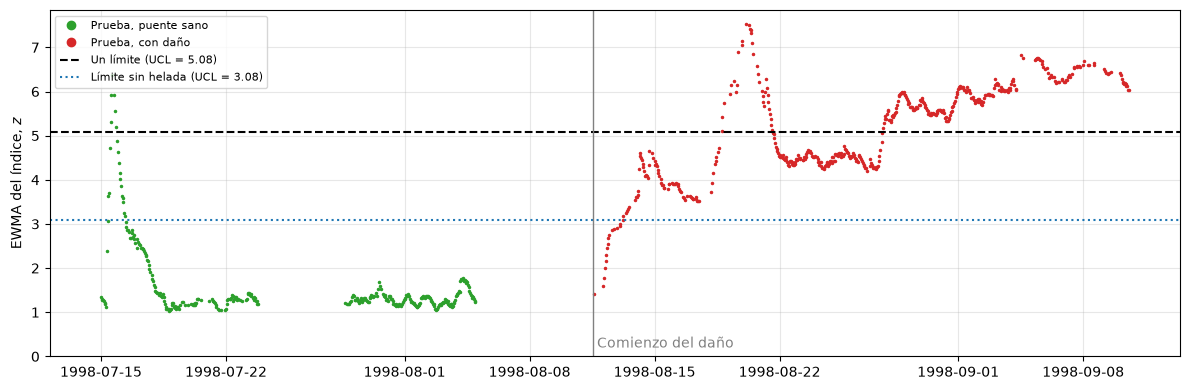

**Figura 15.** EWMA (Ec. 2, λ = 0.1) del índice de daño en los bloques de prueba y límites de alarma (Ec. 9). En la prueba no hubo heladas, así que con dos límites se usa siempre el límite sin helada. Las mediciones de la preparación del daño (05.08 al 11.08.1998) están excluidas.

In [33]:
healthy_test = test_data[test_data["block"] == "Prueba, puente sano"]
damaged = test_data[test_data["block"] == "Prueba, con daño"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(healthy_test["start"], healthy_test["z"], ".", markersize=3, color=BLOCK_COLORS["Prueba, puente sano"],
        label="Prueba, puente sano")
ax.plot(damaged["start"], damaged["z"], ".", markersize=3, color=BLOCK_COLORS["Prueba, con daño"],
        label="Prueba, con daño")
ax.axhline(LIMIT_SINGLE, color="black", linestyle="--", label=f"Un límite (UCL = {LIMIT_SINGLE:.2f})")
ax.axhline(LIMIT_NO_FROST, color="tab:blue", linestyle=":", label=f"Límite sin helada (UCL = {LIMIT_NO_FROST:.2f})")
ax.axvline(DAMAGE_START, color="gray", linewidth=1)
ax.text(DAMAGE_START, 0.2, " Comienzo del daño", color="gray")
ax.set_ylim(0, None)
ax.set_ylabel("EWMA del índice, $z$")
ax.legend(markerscale=4, loc="upper left", fontsize=8)
ax.grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 15, "EWMA (Ec. 2, λ = 0.1) del índice de daño en los bloques de prueba y límites de alarma (Ec. 9). "
            "En la prueba no hubo heladas, así que con dos límites se usa siempre el límite sin helada. Las "
            "mediciones de la preparación del daño (05.08 al 11.08.1998) están excluidas.")

In [34]:
# Alarms and detection delay for one limit and for two limits
rows = []
for limit_name, limit in [("Un límite", LIMIT_SINGLE), ("Dos límites", test_data["limit_two"])]:
    alarm = test_data["z"] > limit

    # A new alarm starts when z goes above the limit (it was below at the previous measurement)
    previous_alarm = alarm.shift(1, fill_value=False)
    new_alarm = alarm & ~previous_alarm

    is_healthy = test_data["block"] == "Prueba, puente sano"
    is_damaged = test_data["block"] == "Prueba, con daño"

    damage_alarm_times = test_data.loc[alarm & is_damaged, "start"]
    first_alarm = damage_alarm_times.min()
    delay_hours = (first_alarm - DAMAGE_START).total_seconds() / 3600

    rows.append({
        "Límite": limit_name,
        "Falsas alarmas (puente sano)": new_alarm[is_healthy].sum(),
        "Horas en falsa alarma": alarm[is_healthy].sum(),
        "Primera alarma con daño": first_alarm.strftime("%d.%m.%Y %H:%M"),
        "Retraso de detección (h)": delay_hours,
        "% de mediciones con daño en alarma": 100 * alarm[is_damaged].mean(),
    })
alarm_table = pd.DataFrame(rows)

show_table(alarm_table, 15, "Falsas alarmas en la prueba con el puente sano y detección del daño, con un límite y "
           "con dos límites (Ec. 9).", decimals=1)

**Tabla 15.** Falsas alarmas en la prueba con el puente sano y detección del daño, con un límite y con dos límites (Ec. 9).

Límite,Falsas alarmas (puente sano),Horas en falsa alarma,Primera alarma con daño,Retraso de detección (h),% de mediciones con daño en alarma
Un límite,1,6,18.08.1998 18:00,172.8,53.8
Dos límites,1,20,13.08.1998 06:00,40.8,96.8


**Resultados:**

- **Entrenamiento (Figura 14):** sin helada, la EWMA se mantiene entre 0.8 y 2 casi todo el tiempo. Sube solo en las heladas: hasta 4.7 a comienzos de diciembre y hasta 5.1 en la helada fuerte de febrero. Por eso el límite único (5.08) lo fija la helada de febrero, y el límite sin helada es mucho más bajo (3.08).
- **Detección del daño (Tabla 15 y Figura 15):**
  - **Con un límite**, la primera alarma llega el 18.08.1998, 173 h (7 días) después del comienzo del daño, y solo el 54 % de las mediciones con daño quedan en alarma: entre el 22 y el 27.08 la EWMA vuelve a bajar del límite.
  - **Con dos límites**, la alarma llega el 13.08.1998 a las 06:00, **41 h después del comienzo del daño**, y el 97 % de las mediciones con daño quedan en alarma.
  - La EWMA sube desde el primer día del daño y crece por escalones a medida que se agrava, como el índice (Figura 13).
- **Falsas alarmas con el puente sano (Tabla 15):** hay una sola, el 15.07.1998, con los dos tipos de límite (6 h en alarma con un límite, 20 h con dos). La causa es el error de identificación de $f_1$ de 7 horas seguidas visto en la sección 7: la EWMA llega a 5.9, por encima incluso del límite único. Fuera de ese episodio, la EWMA del puente sano se queda entre 1 y 1.8, lejos del límite sin helada.

**Decisión:** se usan dos límites, con y sin helada. Detectan el daño 5 días antes y con la misma cantidad de falsas alarmas.

**Limitaciones:**

- La prueba no tiene heladas (es verano), así que el límite con helada no se pudo probar con datos nuevos.
- La prueba con el puente sano dura solo 3 semanas. Una falsa alarma en 3 semanas es una estimación con mucha incertidumbre.
- $\lambda = 0.1$ y la ventana de 72 h se eligieron a criterio, no se ajustaron. No se ajustan con los datos con daño, porque eso daría un resultado demasiado optimista.
- Un error de identificación que dura varias horas, como el del 15.07, la EWMA no lo filtra. Para no dar la alarma, haría falta, por ejemplo, revisar la identificación modal de esas horas antes de avisar.

---
<a id="sec9"></a>
## 9. Evaluación

Se evalúa el sistema completo (modelo → residuos → índice de Mahalanobis → EWMA → límites) con tres preguntas:

1. ¿Cuánto aporta la corrección por temperatura? Se repite todo con la referencia trivial (sin corrección) y con la regresión lineal.
2. ¿Qué tanto depende el resultado de $\lambda$?
3. ¿Qué tan bien separa el sistema el puente sano del dañado, para cualquier límite? (curva ROC)

Los bloques de prueba se usan solo para medir; ninguna decisión del sistema se toma con ellos.

### 9.1 Funciones del sistema completo

Las mismas operaciones de las secciones 7 y 8, escritas como funciones para poder repetirlas con otros modelos y otros valores de $\lambda$.

In [35]:
# 1. Test residuals (Eq. 1) of the trivial reference and of the linear regression, with models fitted on all
#    the training measurements (the training residuals are the out-of-fold ones of Section 4)
for mode in [1, 2, 3]:
    target = f"f{mode}"

    # Trivial reference: the mean frequency of the training block (no temperature correction)
    test_data[f"mean_res_f{mode}"] = test_data[target] - train_data[target].mean()

    # Linear regression (Eq. 5)
    model = LinearRegression()
    model.fit(train_data[FEATURES], train_data[target])
    test_data[f"linear_res_f{mode}"] = test_data[target] - model.predict(test_data[FEATURES])

    # Tuned random forest: same residuals as in Section 7
    test_data[f"tuned_res_f{mode}"] = test_data[f"res_f{mode}"]


# 2. Mahalanobis distance (Eq. 8) of every row of a table of residuals
def mahalanobis_distance(residuals, mean, cov_inv):
    distances = []
    for r in residuals:                       # r = [r1, r2, r3] of one measurement
        difference = r - mean
        distances.append(np.sqrt(difference @ cov_inv @ difference))
    return np.array(distances)


# 3. Whole system for one model: damage index, EWMA and limits (Sections 7 and 8)
def damage_detection(prefix, lam, two_limits=True):
    columns = [f"{prefix}_res_f1", f"{prefix}_res_f2", f"{prefix}_res_f3"]
    train_residuals = train_data[columns].to_numpy()
    test_residuals = test_data[columns].to_numpy()

    # Damage index (Eq. 8), with the mean and covariance of the training residuals
    mean = train_residuals.mean(axis=0)
    cov_inv = np.linalg.inv(np.cov(train_residuals, rowvar=False))
    train_d = mahalanobis_distance(train_residuals, mean, cov_inv)
    test_d = mahalanobis_distance(test_residuals, mean, cov_inv)

    # EWMA (Eq. 2), starting at the mean index of the training block
    train_z = np.array(ewma(train_d, lam, train_d.mean()))
    test_z = np.array(ewma(test_d, lam, train_d.mean()))

    if two_limits:
        # Two limits (Eq. 9): highest training EWMA with and without frost in the last 72 h
        train_frost = train_data["frost_last_72h"].to_numpy()
        limit_frost = train_z[train_frost].max()
        limit_no_frost = train_z[~train_frost].max()
        # Limit of each test measurement: the frost limit where there was frost, the other one elsewhere
        test_limit = np.where(test_data["frost_last_72h"], limit_frost, limit_no_frost)
    else:
        # One limit (Eq. 9): highest training EWMA, the same for every test measurement
        test_limit = np.full(len(test_d), train_z.max())

    return test_d, test_z, test_limit


# 4. False alarms and detection of the damage (as in Table 15)
is_healthy = (test_data["block"] == "Prueba, puente sano").to_numpy()
is_damaged = (test_data["block"] == "Prueba, con daño").to_numpy()
test_times = test_data["start"].to_numpy()


def alarm_summary(test_z, test_limit):
    alarm = test_z > test_limit
    previous_alarm = np.concatenate([[False], alarm[:-1]])     # alarm at the previous measurement
    new_alarm = alarm & ~previous_alarm

    damage_alarm_times = test_times[alarm & is_damaged]
    if len(damage_alarm_times) > 0:
        first_alarm = pd.Timestamp(damage_alarm_times[0])
        first_alarm_text = first_alarm.strftime("%d.%m.%Y %H:%M")
        delay_hours = (first_alarm - DAMAGE_START).total_seconds() / 3600
    else:
        first_alarm_text = "Sin alarma"
        delay_hours = np.nan

    return {
        "Falsas alarmas (puente sano)": new_alarm[is_healthy].sum(),
        "Horas en falsa alarma": alarm[is_healthy].sum(),
        "Primera alarma con daño": first_alarm_text,
        "Retraso de detección (h)": delay_hours,
        "% de mediciones con daño en alarma": 100 * alarm[is_damaged].mean(),
    }

### 9.2 Aporte de la corrección por temperatura

Se repite el sistema completo con los residuos de los tres modelos, con $\lambda = 0.1$, con un límite y con dos límites:

- **Sin corrección (referencia trivial):** el residuo es la frecuencia medida menos la media del entrenamiento. Es lo que se vigilaría si no se tuviera en cuenta la temperatura.
- **Regresión lineal** (sección 4).
- **Random forest ajustado** (sección 6), el modelo elegido.

In [36]:
MODELS = [("Sin corrección (media)", "mean"), ("Regresión lineal", "linear"), ("Random forest ajustado", "tuned")]

results = {}      # damage index, EWMA and limit of each model (two limits), used in the next figures
rows = []
for limit_name, two_limits in [("Un límite", False), ("Dos límites", True)]:
    for model_name, prefix in MODELS:
        test_d, test_z, test_limit = damage_detection(prefix, LAMBDA, two_limits)
        if two_limits:
            results[model_name] = {"d": test_d, "z": test_z, "limit": test_limit}

        row = {"Límite": limit_name, "Modelo": model_name, "UCL en la prueba": test_limit[0]}   # no frost in the test
        row.update(alarm_summary(test_z, test_limit))
        rows.append(row)
models_table = pd.DataFrame(rows)

show_table(models_table, 16, "Falsas alarmas y detección del daño del sistema completo (Ec. 8, Ec. 2 con λ = 0.1 y "
           "Ec. 9) con los residuos de cada modelo, con un límite y con dos límites.", decimals=1)

**Tabla 16.** Falsas alarmas y detección del daño del sistema completo (Ec. 8, Ec. 2 con λ = 0.1 y Ec. 9) con los residuos de cada modelo, con un límite y con dos límites.

Límite,Modelo,UCL en la prueba,Falsas alarmas (puente sano),Horas en falsa alarma,Primera alarma con daño,Retraso de detección (h),% de mediciones con daño en alarma
Un límite,Sin corrección (media),4.8,0,0,20.08.1998 03:00,205.8,28.5
Un límite,Regresión lineal,4.9,1,1,19.08.1998 22:00,200.8,50.0
Un límite,Random forest ajustado,5.1,1,6,18.08.1998 18:00,172.8,53.8
Dos límites,Sin corrección (media),2.5,2,38,14.08.1998 03:00,61.8,92.3
Dos límites,Regresión lineal,2.7,1,20,13.08.1998 05:00,39.8,97.0
Dos límites,Random forest ajustado,3.1,1,20,13.08.1998 06:00,40.8,96.8


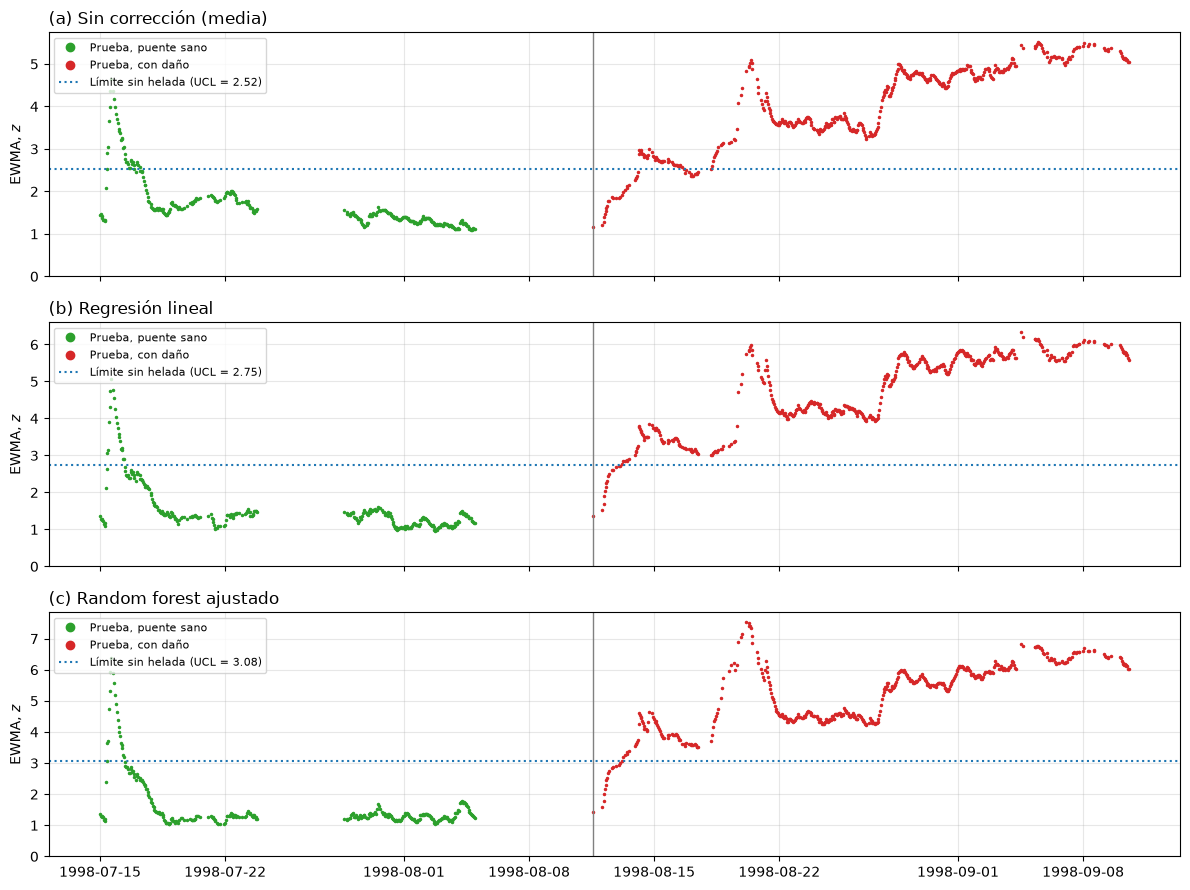

**Figura 16.** EWMA (Ec. 2, λ = 0.1) del índice de daño en los bloques de prueba con los residuos de: (a) la referencia trivial, sin corrección por temperatura, (b) la regresión lineal y (c) el random forest ajustado. La línea vertical marca el comienzo del daño.

In [37]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for i, (model_name, prefix) in enumerate(MODELS):
    z = results[model_name]["z"]
    limit = results[model_name]["limit"]

    axes[i].plot(test_times[is_healthy], z[is_healthy], ".", markersize=3, color=BLOCK_COLORS["Prueba, puente sano"],
                 label="Prueba, puente sano")
    axes[i].plot(test_times[is_damaged], z[is_damaged], ".", markersize=3, color=BLOCK_COLORS["Prueba, con daño"],
                 label="Prueba, con daño")
    axes[i].axhline(limit[0], color="tab:blue", linestyle=":", label=f"Límite sin helada (UCL = {limit[0]:.2f})")
    axes[i].axvline(DAMAGE_START, color="gray", linewidth=1)
    axes[i].set_ylim(0, None)
    axes[i].set_ylabel("EWMA, $z$")
    axes[i].set_title(f"{PANEL_LABELS[i]} {model_name}", loc="left")
    axes[i].legend(markerscale=4, loc="upper left", fontsize=8)
    axes[i].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 16, "EWMA (Ec. 2, λ = 0.1) del índice de daño en los bloques de prueba con los residuos de: (a) la "
            "referencia trivial, sin corrección por temperatura, (b) la regresión lineal y (c) el random forest "
            "ajustado. La línea vertical marca el comienzo del daño.")

**Resultados (Tabla 16 y Figura 16):**

- **Con un límite**, la corrección por temperatura sí se nota: el random forest detecta antes (173 h) que la regresión lineal (201 h) y que sin corrección (206 h), y deja en alarma más mediciones con daño (54 % contra 50 % y 28 %). Con un solo límite, el límite lo fijan las heladas, y el modelo que mejor predice las heladas (el random forest, sección 6) es el que deja el límite más cerca del verano.
- **Con dos límites**, las diferencias se achican:
  - Sin corrección, el daño se detecta igual, pero más tarde (62 h) y con dos falsas alarmas (38 h en alarma).
  - La regresión lineal y el random forest dan casi lo mismo (40 y 41 h, una falsa alarma, 97 % de las mediciones con daño en alarma).
- **Por qué el random forest no gana en la prueba:**
  - Su ventaja está bajo 0 °C: en $f_1$, RMSE de 0.052 Hz contra 0.118 Hz de la regresión lineal (Tablas 9 y 10). Sobre 0 °C los dos modelos se parecen (0.020 contra 0.029 Hz).
  - El daño ocurrió en verano (17 a 39 °C), donde la regresión lineal ya funciona bien.
  - El daño mueve sobre todo $f_2$ (−0.41 Hz, Tabla 13), y sobre 0 °C $f_2$ casi no depende de la temperatura (Figura 3b). Por eso, incluso sin corrección, el cambio de $f_2$ se ve.
- **Los dos límites son, en sí mismos, una corrección por temperatura:** separan las heladas, que es donde está el efecto grande de la temperatura. Por eso, con dos límites, el modelo importa menos.

Con estos datos no se puede probar si el random forest detectaría antes un daño en invierno, porque no hay daño en invierno.

### 9.3 Sensibilidad a $\lambda$

$\lambda$ se fijó en 0.1 sin mirar los datos con daño (sección 8.1). Aquí se repite el sistema con el random forest ajustado y otros valores de $\lambda$, solo para ver cuánto cambia el resultado; no se usa para elegir $\lambda$. Con $\lambda = 1$ no hay suavizado: $z_i = d_i$.

In [38]:
LAMBDA_VALUES = [0.02, 0.05, 0.1, 0.2, 0.5, 1.0]

rows = []
for lam in LAMBDA_VALUES:
    test_d, test_z, test_limit = damage_detection("tuned", lam)
    row = {"λ": lam, "UCL en la prueba": test_limit[0]}
    row.update(alarm_summary(test_z, test_limit))
    rows.append(row)
lambda_table = pd.DataFrame(rows)

show_table(lambda_table, 17, "Falsas alarmas y detección del daño con el random forest ajustado y dos límites (Ec. 9), "
           "según el peso λ de la EWMA (Ec. 2).", decimals=2)

**Tabla 17.** Falsas alarmas y detección del daño con el random forest ajustado y dos límites (Ec. 9), según el peso λ de la EWMA (Ec. 2).

λ,UCL en la prueba,Falsas alarmas (puente sano),Horas en falsa alarma,Primera alarma con daño,Retraso de detección (h),% de mediciones con daño en alarma
0.02,2.13,1,58,13.08.1998 22:00,56.75,95.75
0.05,2.41,1,48,13.08.1998 01:00,35.75,97.37
0.10,3.08,1,20,13.08.1998 06:00,40.75,96.76
0.20,4.02,1,12,14.08.1998 02:00,60.75,87.04
0.50,6.74,2,7,14.08.1998 04:00,62.75,6.48
1.00,12.43,2,2,19.08.1998 16:00,194.75,0.40


**Resultados (Tabla 17):**

- **Sin suavizado ($\lambda = 1$), el sistema casi no funciona:** el límite tiene que ser muy alto (12.4) para no dar falsas alarmas en el entrenamiento, y el daño se detecta 195 h después, con solo el 0.4 % de las mediciones con daño en alarma. La EWMA es imprescindible.
- **Los mejores valores están entre 0.05 y 0.1:** detección en 36–41 h y el 97 % de las mediciones con daño en alarma. El valor elegido a priori ($\lambda = 0.1$) está en ese rango.
- **Con $\lambda$ más pequeño (0.02)**, la EWMA reacciona más lento (57 h) y la falsa alarma del 15.07 dura más (58 h), porque tarda más en olvidar el error.
- **Con $\lambda$ más grande (0.2 a 0.5)**, el límite sube y la detección se atrasa. Con 0.5, solo el 6.5 % de las mediciones con daño queda en alarma.
- La falsa alarma del 15.07.1998 aparece con todos los valores de $\lambda$.

### 9.4 Curva ROC

Los resultados anteriores dependen del límite elegido. La curva ROC (*Receiver Operating Characteristic*) mira todos los límites posibles a la vez. Para cada límite se calcula, en los bloques de prueba:

$$
\text{TPR} = \frac{\text{mediciones con daño sobre el límite}}{\text{mediciones con daño}}, \qquad
\text{FPR} = \frac{\text{mediciones del puente sano sobre el límite}}{\text{mediciones del puente sano}}
\tag{10}
$$

donde TPR (*True Positive Rate*) es la fracción de daño detectado y FPR (*False Positive Rate*) la fracción de falsas alarmas. Al bajar el límite, las dos suben. Un sistema perfecto llega a TPR = 1 con FPR = 0 (esquina superior izquierda); uno que adivina al azar sigue la diagonal.

El área bajo la curva (AUC, *Area Under the Curve*) resume la curva en un número: 1 es separación perfecta y 0.5 es azar. Es la probabilidad de que una medición con daño, elegida al azar, tenga un índice más alto que una del puente sano.

Se calcula para el índice de cada medición, $d$ (Ec. 8), y para la EWMA, $z$ (Ec. 2).

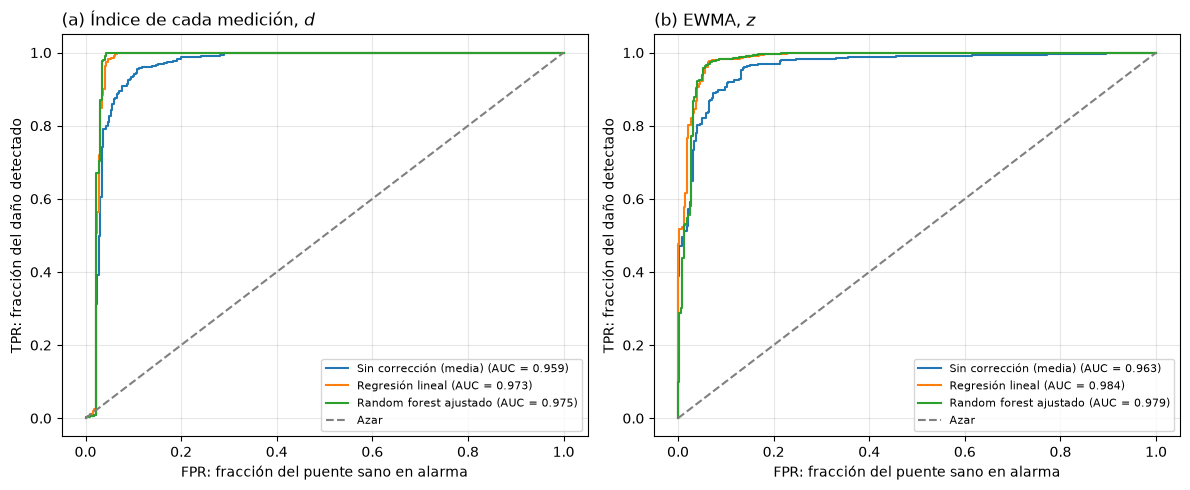

**Figura 17.** Curvas ROC (Ec. 10) en los bloques de prueba para (a) el índice de daño de cada medición y (b) su EWMA (λ = 0.1), con los residuos de cada modelo.

**Tabla 18.** Área bajo la curva ROC (AUC) de cada modelo y puntaje en los bloques de prueba.

Modelo,Puntaje,AUC
Sin corrección (media),d,0.959
Sin corrección (media),z,0.963
Regresión lineal,d,0.973
Regresión lineal,z,0.984
Random forest ajustado,d,0.975
Random forest ajustado,z,0.979


In [39]:
# 1 = damaged, 0 = healthy, for each test measurement
labels = is_damaged.astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
rows = []

for model_name, prefix in MODELS:
    for i, (score_name, score_label) in enumerate([("d", "Índice $d$ (Ec. 8)"), ("z", "EWMA $z$ (Ec. 2)")]):
        score = results[model_name][score_name]
        fpr, tpr, thresholds = roc_curve(labels, score)          # TPR and FPR (Eq. 10) for every limit
        auc = roc_auc_score(labels, score)
        axes[i].plot(fpr, tpr, label=f"{model_name} (AUC = {auc:.3f})")
        rows.append({"Modelo": model_name, "Puntaje": score_name, "AUC": auc})

for i, title in enumerate(["(a) Índice de cada medición, $d$", "(b) EWMA, $z$"]):
    axes[i].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Azar")
    axes[i].set_xlabel("FPR: fracción del puente sano en alarma")
    axes[i].set_ylabel("TPR: fracción del daño detectado")
    axes[i].set_title(title, loc="left")
    axes[i].legend(loc="lower right", fontsize=8)
    axes[i].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 17, "Curvas ROC (Ec. 10) en los bloques de prueba para (a) el índice de daño de cada medición y "
            "(b) su EWMA (λ = 0.1), con los residuos de cada modelo.")

auc_table = pd.DataFrame(rows)
show_table(auc_table, 18, "Área bajo la curva ROC (AUC) de cada modelo y puntaje en los bloques de prueba.", decimals=3)

**Resultados (Figura 17 y Tabla 18):**

- Los tres modelos separan bien el puente sano del dañado: AUC de 0.96 a 0.98.
- La corrección por temperatura mejora la separación: con el índice $d$, de 0.959 sin corrección a 0.973–0.975 con un modelo; con la EWMA, de 0.963 a 0.979–0.984. La regresión lineal y el random forest quedan prácticamente iguales, por la misma razón que en la sección 9.2: la prueba es solo de verano.
- Las curvas no llegan a la esquina superior izquierda: en la parte baja, la fracción de falsas alarmas sube al 2–3 % antes de detectar el daño. Son las mediciones del 15.07.1998, el error de identificación de $f_1$ que tiene índices más altos que muchas mediciones con daño.

**Conclusiones de la evaluación (variante A):**

1. El sistema detecta el primer daño unas **41 h** después de que empieza, y mantiene la alarma en el 97 % de las mediciones con daño (random forest, $\lambda = 0.1$, dos límites).
2. Con el puente sano da **una falsa alarma en 3 semanas**, causada por un error de identificación modal de 7 horas, no por el modelo de temperatura.
3. La EWMA es la parte que más influye en el resultado: sin ella, el daño casi no se detecta.
4. Separar las heladas con dos límites adelanta la detección unos 5 días.
5. En verano, el random forest y la regresión lineal dan el mismo resultado. La ventaja del random forest está en las heladas, y la prueba no tiene heladas.

**Limitaciones:**

- La prueba con el puente sano es corta (3 semanas) y de verano. No hay datos para medir las falsas alarmas ni la detección en invierno con datos nuevos.
- El daño del Z24 es grande en $f_2$ (unas 5 desviaciones estándar del residuo). Un daño más pequeño dependería más de la precisión del modelo.
- Una posible extensión es simular un daño en invierno: restar un cambio pequeño a las frecuencias de las semanas con helada y ver qué modelo lo detecta antes.

---
<a id="sec10"></a>
## 10. Modelo físico (caja gris)

En las secciones 4 a 6, el modelo se eligió por su error: el random forest recibe las variables y encuentra solo la relación. Aquí se hace al revés: **la forma del modelo sale de la física** y solo sus coeficientes se ajustan con los datos (modelo de caja gris). Después se compara con el random forest: si los dos se equivocan parecido, se prefiere el físico, porque se puede interpretar y extrapola mejor.

### 10.1 Mecanismos físicos y términos del modelo

La frecuencia depende de la rigidez $k$ y la masa $m$: $f \propto \sqrt{k/m}$. La temperatura cambia la rigidez, no la masa. Hay cuatro mecanismos:

**Tabla 19.** Mecanismos por los que la temperatura cambia la frecuencia del Z24 y término del modelo que representa a cada uno.

| Mecanismo | Qué pasa | Término |
|---|---|---|
| Rigidez del concreto y del asfalto | Al calentarse, el material se ablanda un poco. Para cambios pequeños, $f$ cambia casi en línea recta con $T$ (la relación casi lineal de la Figura 3). | $\beta_1 T$ |
| Inercia térmica | El sensor mide la superficie, pero la losa se calienta y se enfría con horas de retraso. | $\beta_2 \bar{T}_{24}$ |
| Congelamiento del asfalto | Bajo 0 °C el agua del asfalto se congela y el asfalto se vuelve mucho más rígido: la pendiente cambia en 0 °C (relación bilineal, Peeters y De Roeck, 2001). | $\beta_3 \min(T, 0)$ |
| Congelamiento acumulado (asfalto, apoyos y suelo) | Congelar toma tiempo, porque hay que quitarle calor al agua. La rigidez crece con el frío acumulado, no con la temperatura del momento. Según la ecuación de Stefan, la profundidad congelada crece con la raíz del frío acumulado. | $\beta_4 \sqrt{I}$ |

El modelo, uno por modo, es:

$$
f = \beta_0 + \beta_1 T + \beta_2 \bar{T}_{24} + \beta_3 \min(T, 0) + \beta_4 \sqrt{I}
\tag{11}
$$

donde $T$ es la temperatura del pavimento, $\bar{T}_{24}$ su media móvil de 24 h (Ec. 3), $\min(T, 0)$ vale $T$ bajo 0 °C y 0 sobre 0 °C, e $I$ es el índice de congelamiento. Los coeficientes $\beta$ se ajustan con mínimos cuadrados, como en la regresión lineal (Ec. 5).

**Índice de congelamiento.** Es el frío acumulado en grados-hora (°C·h). Se recorre la serie en orden de tiempo:

$$
I_i = \max\left(0,\; I_{i-1} - T_i \, \Delta t_i\right)
\tag{12}
$$

donde $\Delta t_i$ son las horas desde la medición anterior. Bajo 0 °C, $T_i$ es negativo y el índice crece, más rápido cuanto más frío. Sobre 0 °C, el índice baja: el deshielo también toma tiempo. Nunca es negativo.

Es la variante B (grados-hora bajo cero), con el deshielo descontado. A diferencia de la variante A, distingue −0.5 °C de −6 °C y no vuelve a 0 por un rato corto sobre 0 °C.

**Signos esperados**, si el modelo es físicamente coherente:

- $\beta_1 + \beta_2 < 0$: más calor, menos rigidez y menos frecuencia.
- $\beta_3 < 0$: bajo 0 °C, la frecuencia sube más rápido al bajar la temperatura.
- $\beta_4 > 0$: más frío acumulado, más rigidez y más frecuencia.

In [40]:
# 1. Freezing index in degree-hours (Eq. 12), going through the measurements in time order
freezing_index = []
index_value = 0
previous_start = None

for _, row in data.iterrows():
    if previous_start is not None and not np.isnan(row["T"]):
        hours = (row["start"] - previous_start).total_seconds() / 3600
        # Below 0 °C (T < 0) the index grows; above 0 °C it goes down (thaw); it is never negative
        index_value = max(0, index_value - row["T"] * hours)
    freezing_index.append(index_value)
    previous_start = row["start"]

data["freezing_index"] = freezing_index

# 2. Terms of the physical model (Eq. 11)
data["T_below_zero"] = np.minimum(data["T"], 0)                 # min(T, 0)
data["sqrt_freezing_index"] = np.sqrt(data["freezing_index"])   # square root of I
PHYSICAL_FEATURES = ["T", "T_mean_24h", "T_below_zero", "sqrt_freezing_index"]

# 3. Copy the new terms to the training and test tables (same measurements, same index)
for column in PHYSICAL_FEATURES:
    train_data[column] = data.loc[train_data.index, column]
    test_data[column] = data.loc[test_data.index, column]

print(f"Highest freezing index: {data['freezing_index'].max():.0f} °C·h, "
      f"on {data.loc[data['freezing_index'].idxmax(), 'start']}")

Highest freezing index: 868 °C·h, on 1998-02-09 13:00:10


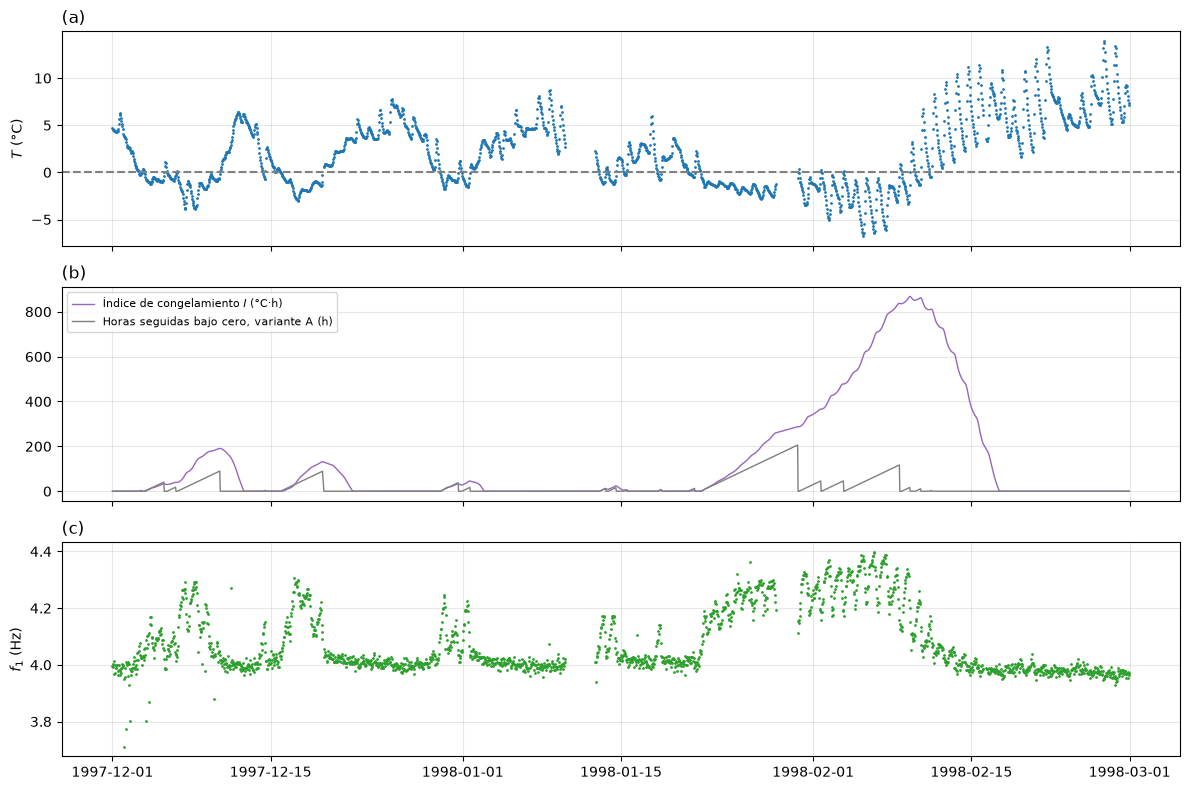

**Figura 18.** Invierno (01.12.1997 al 28.02.1998): (a) temperatura del pavimento, (b) índice de congelamiento (Ec. 12) y contador de la variante A y (c) frecuencia del modo 1.

In [41]:
# Winter only: from 01.12.1997 to 28.02.1998
winter = data[(data["start"] >= "1997-12-01") & (data["start"] < "1998-03-01")]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

# (a) Temperature
axes[0].plot(winter["start"], winter["T"], ".", markersize=2, color="tab:blue")
axes[0].axhline(0, color="gray", linestyle="--")        # 0 °C
axes[0].set_ylabel("$T$ (°C)")

# (b) Freezing index (Eq. 12) and the counter of variant A, for comparison
axes[1].plot(winter["start"], winter["freezing_index"], "-", linewidth=1, color="tab:purple",
             label="Índice de congelamiento $I$ (°C·h)")
axes[1].plot(winter["start"], winter["hours_below_zero"], "-", linewidth=1, color="tab:gray",
             label="Horas seguidas bajo cero, variante A (h)")
axes[1].legend(loc="upper left", fontsize=8)

# (c) Frequency of mode 1
axes[2].plot(winter["start"], winter["f1"], ".", markersize=2, color="tab:green")
axes[2].set_ylabel("$f_1$ (Hz)")

for i in range(3):
    axes[i].set_title(PANEL_LABELS[i], loc="left")
    axes[i].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 18, "Invierno (01.12.1997 al 28.02.1998): (a) temperatura del pavimento, (b) índice de "
            "congelamiento (Ec. 12) y contador de la variante A y (c) frecuencia del modo 1.")

### 10.2 Validación cruzada y coeficientes

Se usa la misma validación cruzada por semanas de las secciones 4 a 6.

In [42]:
# 1. Cross-validation by weeks: for each fold, fit with the other 4 folds and predict the fold left out
for mode in [1, 2, 3]:
    target = f"f{mode}"
    train_data[f"phys_pred_f{mode}"] = np.nan

    for fold in [1, 2, 3, 4, 5]:
        fit_rows = train_data["fold"] != fold        # measurements used to fit the model
        val_rows = train_data["fold"] == fold        # measurements predicted (validation)

        model = LinearRegression()                   # least squares, as in Eq. 5, with the terms of Eq. 11
        model.fit(train_data.loc[fit_rows, PHYSICAL_FEATURES], train_data.loc[fit_rows, target])
        train_data.loc[val_rows, f"phys_pred_f{mode}"] = model.predict(train_data.loc[val_rows, PHYSICAL_FEATURES])

    # Residuals: measured minus predicted (Eq. 1)
    train_data[f"phys_res_f{mode}"] = train_data[target] - train_data[f"phys_pred_f{mode}"]

# 2. RMSE (Eq. 6) of the physical model, the linear regression and the tuned random forest
rows = []
for mode in [1, 2, 3]:
    for model_name, prefix in [("Regresión lineal", "linear"), ("Modelo físico", "phys"),
                               ("Random forest ajustado", "tuned")]:
        residuals = train_data[f"{prefix}_res_f{mode}"]
        rows.append({
            "Modo": mode,
            "Modelo": model_name,
            "RMSE total (Hz)": rmse(residuals),
            "RMSE bajo 0 °C (Hz)": rmse(residuals[below_zero]),
            "RMSE sobre 0 °C (Hz)": rmse(residuals[~below_zero]),
        })
physical_rmse_table = pd.DataFrame(rows)

show_table(physical_rmse_table, 20, "RMSE (Ec. 6) de la validación cruzada por semanas de la regresión lineal "
           "(sección 4), el modelo físico (Ec. 11) y el random forest ajustado (sección 6).", decimals=3)

# 3. Coefficients of the physical model fitted with all the training measurements
rows = []
for mode in [1, 2, 3]:
    model = LinearRegression()
    model.fit(train_data[PHYSICAL_FEATURES], train_data[f"f{mode}"])
    rows.append({
        "Modo": mode,
        "β0 (Hz)": model.intercept_,
        "β1, T (Hz/°C)": model.coef_[0],
        "β2, T media 24 h (Hz/°C)": model.coef_[1],
        "β3, min(T, 0) (Hz/°C)": model.coef_[2],
        "β4, √I (Hz/√(°C·h))": model.coef_[3],
        "β1 + β2 (Hz/°C)": model.coef_[0] + model.coef_[1],
    })
coefficients_table = pd.DataFrame(rows)

show_table(coefficients_table, 21, "Coeficientes del modelo físico (Ec. 11) ajustado con todas las mediciones "
           "válidas del entrenamiento.", decimals=4)

**Tabla 20.** RMSE (Ec. 6) de la validación cruzada por semanas de la regresión lineal (sección 4), el modelo físico (Ec. 11) y el random forest ajustado (sección 6).

Modo,Modelo,RMSE total (Hz),RMSE bajo 0 °C (Hz),RMSE sobre 0 °C (Hz)
1,Regresión lineal,0.055,0.118,0.029
1,Modelo físico,0.036,0.068,0.025
1,Random forest ajustado,0.028,0.052,0.020
2,Regresión lineal,0.108,0.215,0.067
2,Modelo físico,0.071,0.099,0.063
2,Random forest ajustado,0.086,0.153,0.065
3,Regresión lineal,0.162,0.315,0.106
3,Modelo físico,0.117,0.172,0.102
3,Random forest ajustado,0.106,0.153,0.094


**Tabla 21.** Coeficientes del modelo físico (Ec. 11) ajustado con todas las mediciones válidas del entrenamiento.

Modo,β0 (Hz),"β1, T (Hz/°C)","β2, T media 24 h (Hz/°C)","β3, min(T, 0) (Hz/°C)","β4, √I (Hz/√(°C·h))",β1 + β2 (Hz/°C)
1,4.0198,-0.0007,-0.0038,-0.0736,0.0026,-0.0045
2,5.1396,0.0042,-0.0015,-0.0747,0.0086,0.0027
3,10.1688,-0.0038,-0.0057,-0.1847,0.0064,-0.0095


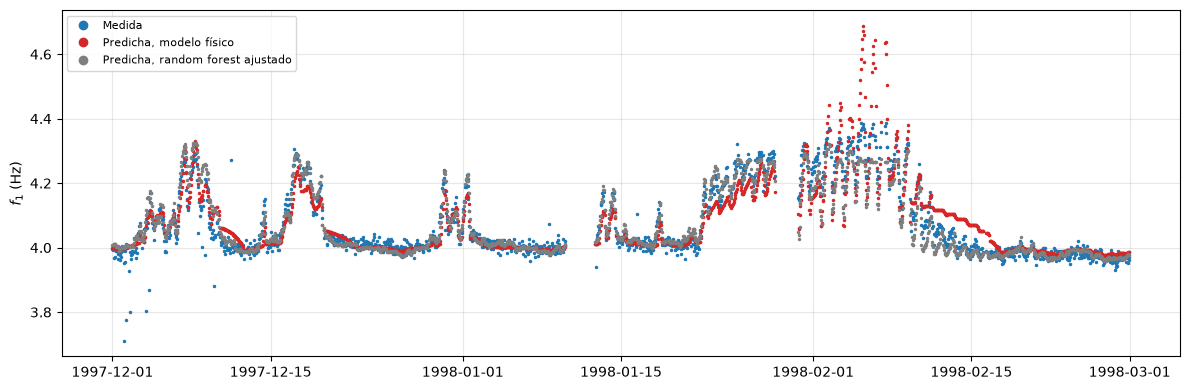

**Figura 19.** Frecuencia del modo 1 medida y predicha en la validación cruzada por semanas, en el invierno (01.12.1997 al 28.02.1998), por el modelo físico (Ec. 11) y por el random forest ajustado.

In [43]:
# Winter only, training measurements
winter_train = train_data[(train_data["start"] >= "1997-12-01") & (train_data["start"] < "1998-03-01")]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(winter_train["start"], winter_train["f1"], ".", markersize=3, color="tab:blue", label="Medida")
ax.plot(winter_train["start"], winter_train["phys_pred_f1"], ".", markersize=3, color="tab:red",
        label="Predicha, modelo físico")
ax.plot(winter_train["start"], winter_train["tuned_pred_f1"], ".", markersize=3, color="tab:gray",
        label="Predicha, random forest ajustado")
ax.set_ylabel("$f_1$ (Hz)")
ax.legend(markerscale=4, loc="upper left", fontsize=8)
ax.grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 19, "Frecuencia del modo 1 medida y predicha en la validación cruzada por semanas, en el invierno "
            "(01.12.1997 al 28.02.1998), por el modelo físico (Ec. 11) y por el random forest ajustado.")

**Resultados (Tablas 20 y 21, Figuras 18 y 19):**

- **Error (Tabla 20):** con 5 coeficientes, el modelo físico queda entre la regresión lineal y el random forest en $f_1$ y $f_3$. En $f_2$ es el mejor de los tres (0.071 Hz contra 0.086 Hz del random forest), sobre todo bajo 0 °C (0.099 contra 0.153 Hz).
- **Coeficientes (Tabla 21):**
  - $eta_3 < 0$ y $eta_4 > 0$ en los tres modos, como se esperaba. En $f_1$, la pendiente bajo 0 °C es unas 17 veces la de sobre 0 °C (−0.078 contra −0.0045 Hz/°C). Es el quiebre del congelamiento del asfalto.
  - $eta_1 + eta_2 < 0$ en $f_1$ y $f_3$. En $f_2$ es pequeño y positivo (+0.003 Hz/°C): sobre 0 °C, $f_2$ casi no depende de la temperatura (Figura 3b), y ninguno de los cuatro mecanismos explica esa pendiente.
  - $eta_1$ y $eta_2$ por separado no se interpretan: $T$ y $ar{T}_{24}$ se mueven juntas, y solo su suma es estable.
- **Índice de congelamiento (Figura 18):** sigue mejor a $f_1$ que la variante A. En la helada de febrero crece hasta 868 °C·h y no se reinicia en los ratos cortos sobre 0 °C.
- **Dónde falla el modelo físico (Figura 19):**
  - **Semana más fría (02 al 09.02.1998):** predice hasta 4.65 Hz, y la medida no pasa de 4.4 Hz. La rigidez no sigue creciendo cuando el asfalto ya está congelado, y el modelo no tiene ese límite.
  - **Deshielo (11 al 17.02.1998):** la frecuencia medida baja en 2–3 días, y la predicha tarda casi una semana. Con días soleados, el deshielo es más rápido de lo que supone la Ec. 12.
  - Estos dos episodios explican casi toda la ventaja del random forest en $f_1$.

### 10.3 Detección del daño con el modelo físico

Se repite el sistema completo de la sección 9 (índice de Mahalanobis, EWMA con $\lambda = 0.1$ y límites), con los residuos del modelo físico. El modelo final se entrena con todas las mediciones válidas del entrenamiento; en el entrenamiento se usan los residuos fuera del fold.

In [44]:
# 1. Test residuals (Eq. 1) of the physical model fitted with all the training measurements
for mode in [1, 2, 3]:
    model = LinearRegression()
    model.fit(train_data[PHYSICAL_FEATURES], train_data[f"f{mode}"])
    test_data[f"phys_res_f{mode}"] = test_data[f"f{mode}"] - model.predict(test_data[PHYSICAL_FEATURES])

# 2. Whole system with the random forest and with the physical model, with one and two limits
rows = []
for limit_name, two_limits in [("Un límite", False), ("Dos límites", True)]:
    for model_name, prefix in [("Random forest ajustado", "tuned"), ("Modelo físico", "phys")]:
        test_d, test_z, test_limit = damage_detection(prefix, LAMBDA, two_limits)

        row = {"Límite": limit_name, "Modelo": model_name, "UCL en la prueba": test_limit[0]}
        row.update(alarm_summary(test_z, test_limit))
        row["AUC de d"] = roc_auc_score(labels, test_d)        # area under the ROC curve (Section 9.4)
        row["AUC de z"] = roc_auc_score(labels, test_z)
        rows.append(row)
physical_detection_table = pd.DataFrame(rows)

show_table(physical_detection_table, 22, "Falsas alarmas, detección del daño y AUC del sistema completo (Ec. 8, "
           "Ec. 2 con λ = 0.1 y Ec. 9) con los residuos del random forest ajustado y del modelo físico (Ec. 11).",
           decimals=2)

**Tabla 22.** Falsas alarmas, detección del daño y AUC del sistema completo (Ec. 8, Ec. 2 con λ = 0.1 y Ec. 9) con los residuos del random forest ajustado y del modelo físico (Ec. 11).

Límite,Modelo,UCL en la prueba,Falsas alarmas (puente sano),Horas en falsa alarma,Primera alarma con daño,Retraso de detección (h),% de mediciones con daño en alarma,AUC de d,AUC de z
Un límite,Random forest ajustado,5.08,1,6,18.08.1998 18:00,172.75,53.85,0.97,0.98
Un límite,Modelo físico,5.76,0,0,19.08.1998 15:00,193.75,52.83,0.98,0.99
Dos límites,Random forest ajustado,3.08,1,20,13.08.1998 06:00,40.75,96.76,0.97,0.98
Dos límites,Modelo físico,2.99,1,20,12.08.1998 15:00,25.75,97.98,0.98,0.99


**Resultados (Tabla 22):**

- **Con dos límites**, el modelo físico detecta el daño **26 h** después de que empieza, contra 41 h del random forest. Tiene la misma falsa alarma del 15.07.1998 y deja en alarma el 98 % de las mediciones con daño.
- **Con un límite**, el modelo físico no da falsas alarmas, pero detecta más tarde (194 h contra 173 h).
- **AUC:** 0.98 para $d$ y 0.99 para $z$, un poco más que el random forest.
- Hay un solo evento de daño. Una diferencia de 15 h no basta para decir que un modelo detecta antes que el otro en general.

**Conclusiones del modelo físico:**

1. **La física sola explica casi toda la dispersión.** Con cuatro términos, cada uno con un mecanismo detrás, el error queda cerca del random forest, y en $f_2$ por debajo.
2. **El random forest solo gana donde el modelo físico simplifica la física:** el límite de la rigidez en la helada más fuerte y la velocidad del deshielo.
3. **En la detección del daño, el modelo físico funciona al menos tan bien** como el random forest.
4. **Ventajas del modelo físico:** sus coeficientes se pueden revisar (signos y magnitudes) y extrapola de forma controlada. Por ser lineal, en una helada más fría que las del entrenamiento tiende a predecir de más, como en la semana del 02.02.1998. El random forest, en cambio, se queda en el valor más alto que vio.